In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    StratifiedShuffleSplit, StratifiedKFold,
    RandomizedSearchCV, cross_val_score
)
#from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef

from sklearn.metrics import (confusion_matrix, classification_report)
from skopt import BayesSearchCV
from skopt.space import Real, Categorical, Integer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import matplotlib as mpl
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, make_scorer
from matplotlib.patches import Patch
from sklearn.preprocessing import MinMaxScaler
import shap
from sklearn.model_selection import cross_validate
import warnings

warnings.filterwarnings('ignore')
import re

from matplotlib.patches import Circle

import os
from typing import List

from sklearn.inspection import permutation_importance

from sklearn.cluster import KMeans
import math
from sklearn.metrics import silhouette_score

from sklearn.inspection import PartialDependenceDisplay

from matplotlib.ticker import AutoMinorLocator


import joblib

/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
! pip freeze > /home/digifort/Documents/Research/bi2te3_env_requirements.txt

In [2]:
df = pd.read_csv("/home/digifort/Documents/Research/BiTe_thesis/my_paper/PCA/n_PC3/PCA_with_Defect_Types.csv")

In [3]:
df_org = df.copy()

In [4]:
df_org

,PC1,PC2,PC3,Defect_Type,structures,carrier_type
0,-0.536303,-1.105306,0.492782,V$_{Bi} - 5 \%$,2,p
1,-0.763957,-1.388229,-1.468762,V$_{Te1} - 5 \%$,3,i
2,-0.837809,-0.977521,-1.912788,V$_{Te2} - 15 \%$,4,p
3,1.972408,-0.371654,-0.937943,A$_{Te@Bi} - 5 \%$,5,n
4,-0.554138,-2.212283,-0.541010,A$_{Bi@Te2} - 10 \%$,6,p
...,...,...,...,...,...,...
99,-1.942535,-0.364596,0.103168,A$_{Te@Bi} - 20 \%$,112,n
100,-0.255638,-1.394088,2.238030,A$_{Bi@Te1} - 20 \%$,114,p
101,2.087099,0.207045,0.452741,A$_{Bi@Te1} - 20 \%$,116,p
102,-1.993772,-1.035521,-0.270218,A$_{Te@Bi} - 20 \%$,117,n


In [5]:
structures = list(df.structures)
c_type = list(df.carrier_type)
defect_type = list(df.Defect_Type)

In [6]:
df = df.drop(columns=['carrier_type', 'Defect_Type'])
df = df.dropna(axis=1, how='any')

### Data

In [7]:
train_df = pd.read_csv("split_05_train.csv")[["structures", "carrier_type"]]
test_df  = pd.read_csv("split_05_test.csv")[["structures", "carrier_type"]]

In [8]:
df_pca = df.copy()

In [9]:
df_pca["structures"] = df_pca["structures"].astype(int)
train_df["structures"] = train_df["structures"].astype(int)
test_df["structures"]  = test_df["structures"].astype(int)

In [10]:
train_join = df_pca.merge(train_df, on="structures", how="inner")
test_join  = df_pca.merge(test_df,  on="structures", how="inner")

In [11]:
X_train = train_join[[c for c in train_join.columns if c.startswith("PC")]].to_numpy()
X_test  = test_join[[c for c in test_join.columns if c.startswith("PC")]].to_numpy()

In [12]:
y_train = train_join["carrier_type"].to_numpy()
y_test  = test_join["carrier_type"].to_numpy()

In [13]:
test_strucs = list(test_join.structures)

In [14]:
test_join

,PC1,PC2,PC3,structures,carrier_type
0,1.827503,0.897096,-1.390573,10,i
1,2.132444,-0.635340,1.104415,11,p
2,-2.665997,1.768632,0.225940,16,i
3,0.439627,1.222936,0.583518,21,p
4,3.451529,0.982238,-1.074355,31,i
5,1.837252,0.881876,-1.403496,38,i
6,0.668695,-0.680837,-0.495084,40,n
7,0.662316,-1.622642,0.419781,49,p
8,3.630735,0.064620,0.440594,52,p
9,2.083669,-0.631579,0.289159,53,p


In [15]:
X_new = df_pca.filter(regex=r"^PC")

In [16]:
X_train_new = train_join.filter(regex=r"^PC")
X_test_new = test_join.filter(regex=r"^PC")

### Define scoring metrics

In [17]:
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'f1_macro': make_scorer(f1_score, average='macro'),
    'precision_macro': make_scorer(precision_score, average='macro'),
    'recall_macro': make_scorer(recall_score, average='macro'),
    'mcc': make_scorer(matthews_corrcoef)
}

In [18]:
# evaluation metrics
def evaluate(y_true, y_pred, average='weighted'):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred, average=average),
        'Precision': precision_score(y_true, y_pred, average=average),
        'Recall': recall_score(y_true, y_pred, average=average),
        'MCC': matthews_corrcoef(y_true, y_pred)
    }

# confusion matrix plotting function
def plot_confusion(y_true, y_pred, labels): #, title
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=labels, yticklabels=labels)
   # plt.title(f'Confusion Matrix - {title}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    filename = f"confusion_matrix.png"
    plt.savefig(filename, dpi=600, bbox_inches='tight')
    plt.show()

In [20]:
best_model = SVC(C=10.0, gamma=0.06398100414211706, kernel= 'rbf', class_weight="balanced", random_state=42, probability=True)
#best_model = SVC(C=10.0, gamma=0.07262393528576296, kernel= 'rbf', class_weight="balanced", random_state=42, probability=True)
#best_model = SVC(C=10.0, gamma=0.07425808470281256, kernel= 'rbf', class_weight="balanced", random_state=42, probability=True)
best_model.fit(X_train, y_train)

SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706,
    probability=True, random_state=42)

In [5]:

def evaluate_classifier(
    model,
    X_train, y_train,
    X_test,  y_test,
    X_test_structures=None,
    name="Model",
    label_encoder=None,
    plot_confusion_fn=None,
    save_dir=None,                 
    zero_division=0,              
):
    # predict
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)

    # if inverse transform needed
    if label_encoder is not None:
        y_true_test = y_test
        y_true_train = y_train
        y_pred_test = label_encoder.inverse_transform(y_pred_test)
        y_pred_train = label_encoder.inverse_transform(y_pred_train)
    else:
        y_true_test = y_test
        y_true_train = y_train

    # --- classification reports (string) ---
    report_test_str = classification_report(
        y_true_test, y_pred_test, zero_division=zero_division
    )
    report_train_str = classification_report(
        y_true_train, y_pred_train, zero_division=zero_division
    )

    print(f"Classification Report on Test Set for {name}:\n{report_test_str}")
    print(f"Classification Report on Training Set for {name}:\n{report_train_str}")

    # --- classification reports (dict + df) ---
    report_test_dict = classification_report(
        y_true_test, y_pred_test, output_dict=True, zero_division=zero_division
    )  # output_dict returns a dict [web:1]
    report_train_dict = classification_report(
        y_true_train, y_pred_train, output_dict=True, zero_division=zero_division
    )  # output_dict returns a dict [web:1]

    report_test_df = pd.DataFrame(report_test_dict).T
    report_train_df = pd.DataFrame(report_train_dict).T

    # save reports if requested
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        safe = "".join(c if c.isalnum() or c in ("-", "_") else "_" for c in name)

      #  (save_dir / f"{safe}__report_test.txt").write_text(report_test_str)
      #  (save_dir / f"{safe}__report_train.txt").write_text(report_train_str)

        (save_dir / f"{safe}__report_test.csv").write_text(report_test_df.to_csv())
        (save_dir / f"{safe}__report_train.csv").write_text(report_train_df.to_csv())

       # (save_dir / f"{safe}__report_test.json").write_text(json.dumps(report_test_dict, indent=2))
       # (save_dir / f"{safe}__report_train.json").write_text(json.dumps(report_train_dict, indent=2))

    # global metrics using your evaluate() helper
    test_scores = evaluate(y_true_test,  y_pred_test,  average='macro')
    train_scores = evaluate(y_true_train, y_pred_train, average='macro')

    print(f"\n{name}: Global Metrics (TEST)")
    for k, v in test_scores.items():
        print(f"{k}: {v:.4f}")

    print(f"\n{name}: Global Metrics (TRAIN)")
    for k, v in train_scores.items():
        print(f"{k}: {v:.4f}")

    if plot_confusion_fn is not None:
        labels = np.unique(np.concatenate([np.ravel(y_true_test), np.ravel(y_pred_test)]))
        plot_confusion_fn(y_true_test, y_pred_test, labels=labels)

    # misclassified details (test set)
    y_true_test = np.ravel(y_true_test)
    y_pred_test = np.ravel(y_pred_test)

    mis_mask = (y_true_test != y_pred_test)
    mis_idx = np.where(mis_mask)[0]

    mis_df = pd.DataFrame({
        "idx": mis_idx,
        "Structure ID": None if X_test_structures is None else np.asarray(X_test_structures)[mis_mask],
        "True Label": y_true_test[mis_mask],
        "Predicted Label": y_pred_test[mis_mask],
    })

    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X_test)[mis_mask]
        class_labels = model.classes_
        if label_encoder is not None:
            class_labels = label_encoder.inverse_transform(class_labels)
        proba_df = pd.DataFrame(proba, columns=class_labels)
        mis_df = pd.concat([mis_df.reset_index(drop=True), proba_df.reset_index(drop=True)], axis=1)

    print(f"Misclassified sample count for {name}: {mis_mask.sum()}")
    return {
        "y_pred_test": y_pred_test,
        "y_pred_train": np.ravel(y_pred_train),
        "misclassified_mask": mis_mask,
        "misclassified_df": mis_df,
        "report_test_str": report_test_str,
        "report_train_str": report_train_str,
        "report_test_dict": report_test_dict,     
        "report_train_dict": report_train_dict,   
        "report_test_df": report_test_df,
        "report_train_df": report_train_df,
    }


In [23]:
from pathlib import Path

Classification Report on Test Set for SVC_split_1_nPC_3:
              precision    recall  f1-score   support

           i       0.67      1.00      0.80         4
           n       1.00      1.00      1.00         5
           p       1.00      0.82      0.90        11

    accuracy                           0.90        20
   macro avg       0.89      0.94      0.90        20
weighted avg       0.93      0.90      0.91        20

Classification Report on Training Set for SVC_split_1_nPC_3:
              precision    recall  f1-score   support

           i       0.75      0.90      0.82        20
           n       0.94      0.85      0.89        20
           p       0.98      0.93      0.95        44

    accuracy                           0.90        84
   macro avg       0.89      0.89      0.89        84
weighted avg       0.91      0.90      0.91        84


SVC_split_1_nPC_3: Global Metrics (TEST)
Accuracy: 0.9000
F1 Score: 0.9000
Precision: 0.8889
Recall: 0.9394
MCC: 0.8555

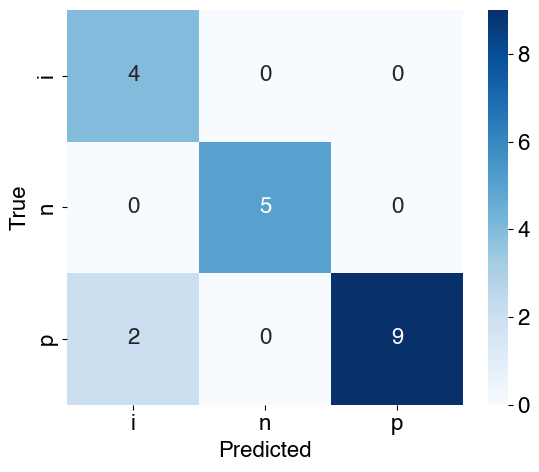

Misclassified sample count for SVC_split_1_nPC_3: 2
   idx  Structure ID True Label Predicted Label         i         n         p
0   12            72          p               i  0.446601  0.012000  0.541399
1   13            84          p               i  0.709370  0.048857  0.241772


In [24]:
out = evaluate_classifier(
    best_model,
    X_train, y_train,
    X_test, y_test,
    X_test_structures=test_join["structures"],
    name="SVC_split_1_nPC_3",
    label_encoder=None,
    plot_confusion_fn=plot_confusion,
    save_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier',
    zero_division=0,
)

misclassified_df = out["misclassified_df"]
training_df = out['report_train_df']
print(misclassified_df.head(10))




In [25]:
out['y_pred_test']

array(['i', 'p', 'i', 'p', 'i', 'i', 'n', 'p', 'p', 'p', 'p', 'n', 'i',
       'i', 'p', 'n', 'n', 'p', 'n', 'p'], dtype=object)

### Save training set predictions

In [26]:
df_train = train_join

In [27]:
df_train['pred'] = out['y_pred_train']

In [28]:
y_train_proba = best_model.predict_proba(X_train_new)

In [29]:
df_train['p_i'] = y_train_proba[:,0]

In [30]:
df_train['p_n'] = y_train_proba[:,1]

In [31]:
df_train['p_p'] = y_train_proba[:,2]

In [32]:
df_train

,PC1,PC2,PC3,structures,carrier_type,pred,p_i,p_n,p_p
0,-0.536303,-1.105306,0.492782,2,p,p,0.062945,0.066173,0.870882
1,-0.763957,-1.388229,-1.468762,3,i,n,0.362171,0.468150,0.169679
2,-0.837809,-0.977521,-1.912788,4,p,i,0.680927,0.238698,0.080374
3,1.972408,-0.371654,-0.937943,5,n,n,0.121902,0.823946,0.054152
4,-0.554138,-2.212283,-0.541010,6,p,p,0.091755,0.068716,0.839529
...,...,...,...,...,...,...,...,...,...
79,2.306113,-0.116912,1.325251,111,p,p,0.028795,0.003432,0.967773
80,-1.942535,-0.364596,0.103168,112,n,n,0.241444,0.558357,0.200199
81,-0.255638,-1.394088,2.238030,114,p,p,0.007767,0.000400,0.991833
82,-1.993772,-1.035521,-0.270218,117,n,n,0.159516,0.728808,0.111676


In [33]:
df_train.to_csv('training_set_predictions.csv', index=False)

In [34]:
y_train_proba

array([[6.29453659e-02, 6.61730298e-02, 8.70881604e-01],
       [3.62171373e-01, 4.68149616e-01, 1.69679012e-01],
       [6.80927325e-01, 2.38698258e-01, 8.03744176e-02],
       [1.21902382e-01, 8.23945728e-01, 5.41518905e-02],
       [9.17549135e-02, 6.87164133e-02, 8.39528673e-01],
       [8.48056694e-02, 8.46455604e-02, 8.30548770e-01],
       [9.58362630e-02, 7.47405830e-02, 8.29423154e-01],
       [7.05266730e-01, 2.24537710e-01, 7.01955596e-02],
       [2.86051363e-01, 7.21133232e-03, 7.06737305e-01],
       [9.01707007e-01, 5.05335580e-02, 4.77594351e-02],
       [1.49385661e-01, 4.49330646e-02, 8.05681274e-01],
       [5.65779346e-02, 1.29628044e-02, 9.30459261e-01],
       [6.49050903e-01, 2.72520672e-01, 7.84284260e-02],
       [9.70553887e-02, 8.22287063e-02, 8.20715905e-01],
       [6.87123253e-01, 2.40765028e-01, 7.21117184e-02],
       [4.72783995e-01, 4.01582787e-01, 1.25633217e-01],
       [2.32941810e-01, 6.24550648e-02, 7.04603125e-01],
       [3.02923613e-02, 3.85691

### Save test set predictions

In [35]:
df_test = test_join

In [36]:
df_test['pred'] = out['y_pred_test']

In [37]:
y_test_proba = best_model.predict_proba(X_test_new)

In [38]:
df_test['p_i'] = y_test_proba[:,0]

In [39]:
df_test['p_n'] = y_test_proba[:,1]

In [40]:
df_test['p_p'] = y_test_proba[:,2]

In [41]:
df_test.to_csv('test_set_predictions.csv', index=False)

In [42]:
df_test

,PC1,PC2,PC3,structures,carrier_type,pred,p_i,p_n,p_p
0,1.827503,0.897096,-1.390573,10,i,i,0.741168,0.198650,0.060182
1,2.132444,-0.635340,1.104415,11,p,p,0.030456,0.003915,0.965629
2,-2.665997,1.768632,0.225940,16,i,i,0.419143,0.020722,0.560135
3,0.439627,1.222936,0.583518,21,p,p,0.148510,0.045923,0.805568
4,3.451529,0.982238,-1.074355,31,i,i,0.447925,0.456679,0.095396
5,1.837252,0.881876,-1.403496,38,i,i,0.739040,0.201474,0.059486
6,0.668695,-0.680837,-0.495084,40,n,n,0.147661,0.551020,0.301319
7,0.662316,-1.622642,0.419781,49,p,p,0.038169,0.007648,0.954184
8,3.630735,0.064620,0.440594,52,p,p,0.089009,0.071717,0.839274
9,2.083669,-0.631579,0.289159,53,p,p,0.079084,0.080318,0.840598


In [43]:
test_df = out['report_test_df']
#
test_df.to_csv('report_test_df.csv', index=False)

### Calibration of platt scaling

In [44]:
from sklearn.model_selection import train_test_split

In [45]:
X_fit, X_calib, y_fit, y_calib = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

In [46]:
from sklearn.calibration import CalibratedClassifierCV
#from sklearn.frozen import FrozenEstimator

In [47]:
base_svc = SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706,
    probability=False, random_state=42)

In [48]:
base_svc.fit(X_fit, y_fit)

SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706, random_state=42)

In [49]:
calibrated_svc = CalibratedClassifierCV(
    estimator= base_svc,  
    method="sigmoid",
    cv='prefit'
)

In [50]:
calibrated_svc.fit(X_calib,y_calib)

CalibratedClassifierCV(cv='prefit',
                       estimator=SVC(C=10.0, class_weight='balanced',
                                     gamma=0.06398100414211706,
                                     random_state=42))

### Save model

In [ ]:
import joblib

In [141]:
joblib.dump(calibrated_svc, "calibrated_svc.joblib")

['calibrated_svc.joblib']

### Inspection of misclassification

In [52]:
mis_idx = [12, 13]  

old_pred = best_model.predict(X_test_new.loc[mis_idx])
old_proba = best_model.predict_proba(X_test_new.loc[mis_idx])

In [53]:
best_model

SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706,
    probability=True, random_state=42)

In [54]:
old_pred

array(['i', 'i'], dtype=object)

In [55]:
new_pred = calibrated_svc.predict(X_test_new.loc[mis_idx])
new_proba = calibrated_svc.predict_proba(X_test_new.loc[mis_idx])

In [56]:
new_pred

array(['p', 'p'], dtype=object)

### Save calibrated SVC train predictions

In [57]:
df_train_calib = train_join

In [58]:
df_train_calib = df_train_calib.drop(columns=['pred', 'p_i', 'p_n', 'p_p'])

In [59]:
df_train_calib

,PC1,PC2,PC3,structures,carrier_type
0,-0.536303,-1.105306,0.492782,2,p
1,-0.763957,-1.388229,-1.468762,3,i
2,-0.837809,-0.977521,-1.912788,4,p
3,1.972408,-0.371654,-0.937943,5,n
4,-0.554138,-2.212283,-0.541010,6,p
...,...,...,...,...,...
79,2.306113,-0.116912,1.325251,111,p
80,-1.942535,-0.364596,0.103168,112,n
81,-0.255638,-1.394088,2.238030,114,p
82,-1.993772,-1.035521,-0.270218,117,n


In [60]:
df_train_calib['pred_carrier_type'] = calibrated_svc.predict(X_train_new)

In [61]:
y_train_calib_proba = calibrated_svc.predict_proba(X_train_new)

In [62]:
df_train_calib['p_i'] = y_train_calib_proba[:,0]

In [63]:
df_train_calib['p_n'] = y_train_calib_proba[:,1]

In [64]:
df_train_calib['p_p'] = y_train_calib_proba[:,2]

In [65]:
df_train_calib

,PC1,PC2,PC3,structures,carrier_type,pred_carrier_type,p_i,p_n,p_p
0,-0.536303,-1.105306,0.492782,2,p,p,0.108840,0.186685,0.704476
1,-0.763957,-1.388229,-1.468762,3,i,i,0.501677,0.195158,0.303165
2,-0.837809,-0.977521,-1.912788,4,p,i,0.523041,0.176685,0.300275
3,1.972408,-0.371654,-0.937943,5,n,n,0.212754,0.540508,0.246737
4,-0.554138,-2.212283,-0.541010,6,p,p,0.111147,0.173451,0.715403
...,...,...,...,...,...,...,...,...,...
79,2.306113,-0.116912,1.325251,111,p,p,0.109334,0.163928,0.726738
80,-1.942535,-0.364596,0.103168,112,n,n,0.217688,0.526466,0.255846
81,-0.255638,-1.394088,2.238030,114,p,p,0.110471,0.146957,0.742572
82,-1.993772,-1.035521,-0.270218,117,n,n,0.210282,0.538711,0.251007


In [66]:
df_train_calib.to_csv('calibrated_training_predictions.csv', index=False)

### Save calibrated SVC test predictions

In [67]:
df_test_calib = test_join

In [68]:
df_test_calib = df_test_calib.drop(columns=['pred', 'p_i', 'p_n', 'p_p'])

In [69]:
df_test_calib['pred_carrier_type'] = calibrated_svc.predict(X_test_new)

In [70]:
df_test_calib

,PC1,PC2,PC3,structures,carrier_type,pred_carrier_type
0,1.827503,0.897096,-1.390573,10,i,i
1,2.132444,-0.635340,1.104415,11,p,p
2,-2.665997,1.768632,0.225940,16,i,p
3,0.439627,1.222936,0.583518,21,p,p
4,3.451529,0.982238,-1.074355,31,i,n
5,1.837252,0.881876,-1.403496,38,i,i
6,0.668695,-0.680837,-0.495084,40,n,n
7,0.662316,-1.622642,0.419781,49,p,p
8,3.630735,0.064620,0.440594,52,p,p
9,2.083669,-0.631579,0.289159,53,p,p


In [71]:
y_test_calib_proba = calibrated_svc.predict_proba(X_test_new)

In [72]:
df_test_calib['p_i'] = y_test_calib_proba[:,0]

In [73]:
df_test_calib['p_n'] = y_test_calib_proba[:,1]

In [74]:
df_test_calib['p_p'] = y_test_calib_proba[:,2]

In [75]:
df_test_calib

,PC1,PC2,PC3,structures,carrier_type,pred_carrier_type,p_i,p_n,p_p
0,1.827503,0.897096,-1.390573,10,i,i,0.503418,0.210150,0.286433
1,2.132444,-0.635340,1.104415,11,p,p,0.107768,0.174738,0.717493
2,-2.665997,1.768632,0.225940,16,i,p,0.273076,0.018696,0.708228
3,0.439627,1.222936,0.583518,21,p,p,0.253245,0.020414,0.726342
4,3.451529,0.982238,-1.074355,31,i,n,0.211821,0.540498,0.247681
5,1.837252,0.881876,-1.403496,38,i,i,0.503067,0.210699,0.286234
6,0.668695,-0.680837,-0.495084,40,n,n,0.215201,0.524874,0.259925
7,0.662316,-1.622642,0.419781,49,p,p,0.108472,0.173107,0.718421
8,3.630735,0.064620,0.440594,52,p,p,0.106976,0.193070,0.699954
9,2.083669,-0.631579,0.289159,53,p,p,0.107573,0.192774,0.699653


In [76]:
df_test_calib.to_csv('calibrated_test_predictions.csv', index=False)

## New analysis

### misclassification on test set

Classification Report on Test Set for SVC_split_5_nPC_3:
              precision    recall  f1-score   support

           i       1.00      0.50      0.67         4
           n       0.71      1.00      0.83         5
           p       0.91      0.91      0.91        11

    accuracy                           0.85        20
   macro avg       0.87      0.80      0.80        20
weighted avg       0.88      0.85      0.84        20

Classification Report on Training Set for SVC_split_5_nPC_3:
              precision    recall  f1-score   support

           i       0.71      0.75      0.73        20
           n       0.94      0.85      0.89        20
           p       0.91      0.93      0.92        44

    accuracy                           0.87        84
   macro avg       0.86      0.84      0.85        84
weighted avg       0.87      0.87      0.87        84


SVC_split_5_nPC_3: Global Metrics (TEST)
Accuracy: 0.8500
F1 Score: 0.8030
Precision: 0.8745
Recall: 0.8030
MCC: 0.7589

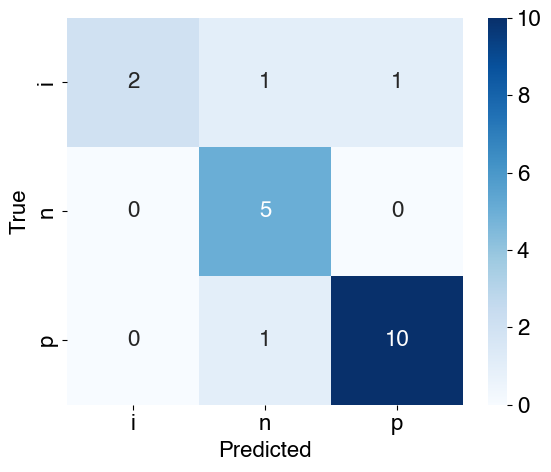

Misclassified sample count for SVC_split_5_nPC_3: 3
   idx  Structure ID True Label Predicted Label         i         n         p
0    2            16          i               p  0.273076  0.018696  0.708228
1    4            31          i               n  0.211821  0.540498  0.247681
2   17           103          p               n  0.089937  0.475785  0.434278


In [77]:
out = evaluate_classifier(
    calibrated_svc,
    X_train_new, y_train,
    X_test_new, y_test,
    X_test_structures=test_join["structures"],
    name="SVC_split_5_nPC_3",
    label_encoder=None,
    plot_confusion_fn=plot_confusion,
    save_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/SVC/new',
    zero_division=0,
)

misclassified_df = out["misclassified_df"]
training_df = out['report_train_df']
print(misclassified_df.head(10))

### Save other information

In [78]:
misclassified_df

,idx,Structure ID,True Label,Predicted Label,i,n,p
0,2,16,i,p,0.273076,0.018696,0.708228
1,4,31,i,n,0.211821,0.540498,0.247681
2,17,103,p,n,0.089937,0.475785,0.434278


### For training set

In [79]:
def evaluate_classifier(
    model,
    X_train, y_train,
    X_test,  y_test,
    X_test_structures=None,
    X_train_structures=None,   # NEW
    name="Model",
    label_encoder=None,
    plot_confusion_fn=None,
    save_dir=None,
    zero_division=0,
):
    # predict
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)

    if label_encoder is not None:
        y_true_test = y_test
        y_true_train = y_train
        y_pred_test = label_encoder.inverse_transform(y_pred_test)
        y_pred_train = label_encoder.inverse_transform(y_pred_train)
    else:
        y_true_test = y_test
        y_true_train = y_train

    report_test_str = classification_report(
        y_true_test, y_pred_test, zero_division=zero_division
    )
    report_train_str = classification_report(
        y_true_train, y_pred_train, zero_division=zero_division
    )

    print(f"Classification Report on Test Set for {name}:\n{report_test_str}")
    print(f"Classification Report on Training Set for {name}:\n{report_train_str}")

    report_test_dict = classification_report(
        y_true_test, y_pred_test, output_dict=True, zero_division=zero_division
    )
    report_train_dict = classification_report(
        y_true_train, y_pred_train, output_dict=True, zero_division=zero_division
    )

    report_test_df = pd.DataFrame(report_test_dict).T
    report_train_df = pd.DataFrame(report_train_dict).T

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        safe = "".join(c if c.isalnum() or c in ("-", "_") else "_" for c in name)

        (save_dir / f"{safe}__report_test.csv").write_text(report_test_df.to_csv())
        (save_dir / f"{safe}__report_train.csv").write_text(report_train_df.to_csv())

    test_scores = evaluate(y_true_test, y_pred_test, average='macro')
    train_scores = evaluate(y_true_train, y_pred_train, average='macro')

    print(f"\n{name}: Global Metrics (TEST)")
    for k, v in test_scores.items():
        print(f"{k}: {v:.4f}")

    print(f"\n{name}: Global Metrics (TRAIN)")
    for k, v in train_scores.items():
        print(f"{k}: {v:.4f}")

    if plot_confusion_fn is not None:
        labels = np.unique(np.concatenate([np.ravel(y_true_test), np.ravel(y_pred_test)]))
        plot_confusion_fn(y_true_test, y_pred_test, labels=labels)

    # ---------- TEST misclassified ----------
    y_true_test = np.ravel(y_true_test)
    y_pred_test = np.ravel(y_pred_test)

    mis_mask_test = (y_true_test != y_pred_test)
    mis_idx_test = np.where(mis_mask_test)[0]

    mis_df_test = pd.DataFrame({
        "idx": mis_idx_test,
        "Structure ID": None if X_test_structures is None else np.asarray(X_test_structures)[mis_mask_test],
        "True Label": y_true_test[mis_mask_test],
        "Predicted Label": y_pred_test[mis_mask_test],
    })

    # ---------- TRAIN misclassified ----------
    y_true_train = np.ravel(y_true_train)
    y_pred_train = np.ravel(y_pred_train)

    mis_mask_train = (y_true_train != y_pred_train)
    mis_idx_train = np.where(mis_mask_train)[0]

    mis_df_train = pd.DataFrame({
        "idx": mis_idx_train,
        "Structure ID": None if X_train_structures is None else np.asarray(X_train_structures)[mis_mask_train],
        "True Label": y_true_train[mis_mask_train],
        "Predicted Label": y_pred_train[mis_mask_train],
    })

    if hasattr(model, "predict_proba"):
        class_labels = model.classes_
        if label_encoder is not None:
            class_labels = label_encoder.inverse_transform(class_labels)

        proba_test = model.predict_proba(X_test)[mis_mask_test]
        proba_train = model.predict_proba(X_train)[mis_mask_train]

        proba_test_df = pd.DataFrame(proba_test, columns=class_labels)
        proba_train_df = pd.DataFrame(proba_train, columns=class_labels)

        mis_df_test = pd.concat([mis_df_test.reset_index(drop=True),
                                 proba_test_df.reset_index(drop=True)], axis=1)
        mis_df_train = pd.concat([mis_df_train.reset_index(drop=True),
                                  proba_train_df.reset_index(drop=True)], axis=1)

    if save_dir is not None:
        (save_dir / f"{safe}__misclassified_test.csv").write_text(mis_df_test.to_csv(index=False))
        (save_dir / f"{safe}__misclassified_train.csv").write_text(mis_df_train.to_csv(index=False))

    print(f"Misclassified sample count for {name} (test): {mis_mask_test.sum()}")
    print(f"Misclassified sample count for {name} (train): {mis_mask_train.sum()}")

    return {
        "y_pred_test": y_pred_test,
        "y_pred_train": y_pred_train,
        "misclassified_mask_test": mis_mask_test,
        "misclassified_mask_train": mis_mask_train,
        "misclassified_df_test": mis_df_test,
        "misclassified_df_train": mis_df_train,
        "report_test_str": report_test_str,
        "report_train_str": report_train_str,
        "report_test_dict": report_test_dict,
        "report_train_dict": report_train_dict,
        "report_test_df": report_test_df,
        "report_train_df": report_train_df,
    }

Classification Report on Test Set for SVC_split_1_nPC_3:
              precision    recall  f1-score   support

           i       1.00      0.50      0.67         4
           n       0.71      1.00      0.83         5
           p       0.91      0.91      0.91        11

    accuracy                           0.85        20
   macro avg       0.87      0.80      0.80        20
weighted avg       0.88      0.85      0.84        20

Classification Report on Training Set for SVC_split_1_nPC_3:
              precision    recall  f1-score   support

           i       0.71      0.75      0.73        20
           n       0.94      0.85      0.89        20
           p       0.91      0.93      0.92        44

    accuracy                           0.87        84
   macro avg       0.86      0.84      0.85        84
weighted avg       0.87      0.87      0.87        84


SVC_split_1_nPC_3: Global Metrics (TEST)
Accuracy: 0.8500
F1 Score: 0.8030
Precision: 0.8745
Recall: 0.8030
MCC: 0.7589

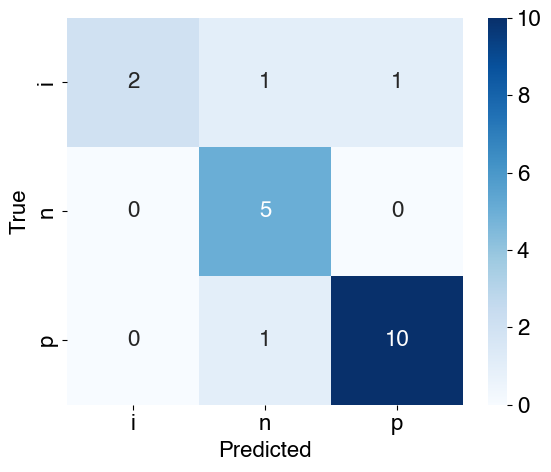

Misclassified sample count for SVC_split_1_nPC_3 (test): 3
Misclassified sample count for SVC_split_1_nPC_3 (train): 11


,idx,Structure ID,True Label,Predicted Label,i,n,p
0,2,4,p,i,0.523041,0.176685,0.300275
1,15,22,n,i,0.509085,0.190974,0.299941
2,21,28,i,p,0.456708,0.018718,0.524574
3,24,33,n,i,0.509162,0.191161,0.299677
4,26,37,i,n,0.212732,0.540158,0.247110
5,49,71,p,i,0.509002,0.191206,0.299792
6,54,79,p,i,0.534104,0.136442,0.329454
7,60,86,i,p,0.460560,0.019014,0.520426
8,61,87,n,i,0.496930,0.218310,0.284759
9,64,90,i,p,0.274159,0.021424,0.704417


In [80]:
out = evaluate_classifier(
    calibrated_svc,
    X_train_new, y_train,
    X_test_new, y_test,
    X_test_structures=test_join["structures"],
    X_train_structures=train_join['structures'],
    name="SVC_split_1_nPC_3",
    label_encoder=None,
    plot_confusion_fn=plot_confusion,
    save_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier',
    zero_division=0,
)

misclassified_train = out["misclassified_df_train"]
#training_df = out['report_train_df']
misclassified_train

In [81]:
misclassified_train.to_csv('training_set_misclassified.csv', index=False)

In [82]:
misclassified_test = out["misclassified_df_test"]
#training_df = out['report_train_df']
misclassified_test

,idx,Structure ID,True Label,Predicted Label,i,n,p
0,2,16,i,p,0.273076,0.018696,0.708228
1,4,31,i,n,0.211821,0.540498,0.247681
2,17,103,p,n,0.089937,0.475785,0.434278


In [83]:
misclassified_test.to_csv('calibrated_test_misclassified.csv', index=False)

In [84]:
defect_map = {
    72:  r'V$_{Bi} - 20 \%$',
    84: r'V$_{Bi} - 20 \%$',
}


# Ensure the IDs match types (int vs str) before mapping
misclassified_df["Defect type"] = misclassified_df["Structure ID"].astype(int).map(defect_map)

In [85]:
misclassified_df

,idx,Structure ID,True Label,Predicted Label,i,n,p,Defect type
0,2,16,i,p,0.273076,0.018696,0.708228,NaN
1,4,31,i,n,0.211821,0.540498,0.247681,NaN
2,17,103,p,n,0.089937,0.475785,0.434278,NaN


Classification Report on Test Set for SVC_split_1_nPC_3:
              precision    recall  f1-score   support

           i       0.75      0.90      0.82        20
           n       0.94      0.85      0.89        20
           p       0.98      0.93      0.95        44

    accuracy                           0.90        84
   macro avg       0.89      0.89      0.89        84
weighted avg       0.91      0.90      0.91        84

Classification Report on Training Set for SVC_split_1_nPC_3:
              precision    recall  f1-score   support

           i       0.75      0.90      0.82        20
           n       0.94      0.85      0.89        20
           p       0.98      0.93      0.95        44

    accuracy                           0.90        84
   macro avg       0.89      0.89      0.89        84
weighted avg       0.91      0.90      0.91        84


SVC_split_1_nPC_3: Global Metrics (TEST)
Accuracy: 0.9048
F1 Score: 0.8888
Precision: 0.8902
Recall: 0.8939
MCC: 0.8485

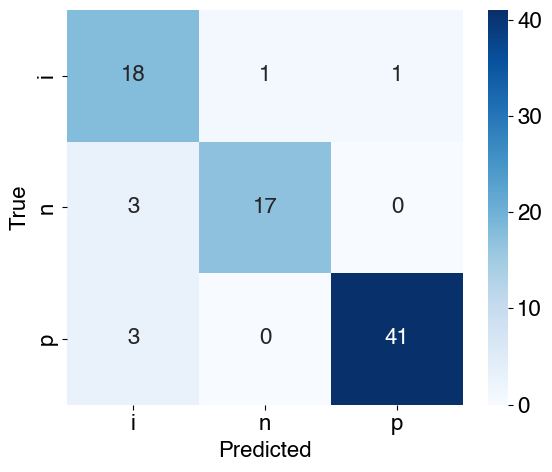

Misclassified sample count for SVC_split_1_nPC_3 (test): 8
Misclassified sample count for SVC_split_1_nPC_3 (train): 8


KeyError: 'misclassified_df'

In [86]:
out = evaluate_classifier(
    best_model,
    X_train, y_train,
    X_train, y_train,
    X_test_structures=train_join["structures"],
    name="SVC_split_1_nPC_3",
    label_encoder=None,
    plot_confusion_fn=plot_confusion,
    save_dir = '/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/training_set_classification',
    zero_division=0,
)

misclassified_df_train = out["misclassified_df"]
#training_df = out['report_train_df']
print(misclassified_df)

In [ ]:
training_df

,precision,recall,f1-score,support
i,0.714286,0.750000,0.731707,20.000000
n,0.944444,0.850000,0.894737,20.000000
p,0.911111,0.931818,0.921348,44.000000
accuracy,0.869048,0.869048,0.869048,0.869048
macro avg,0.856614,0.843939,0.849264,84.000000
weighted avg,0.872184,0.869048,0.869860,84.000000


### Permutation importance

In [15]:
import joblib

In [16]:
clf = joblib.load('calibrated_svc.joblib')

/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/home/digifort/anaconda3/

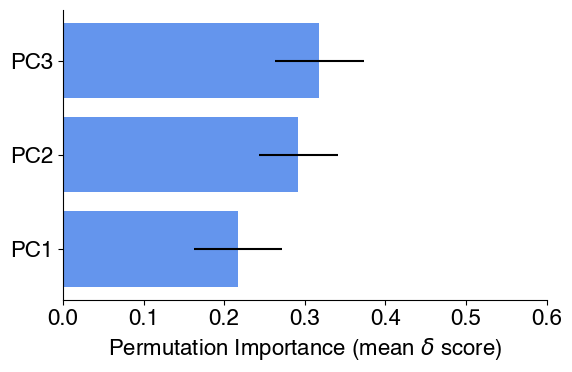

In [ ]:
f1_macro = make_scorer(f1_score, average='macro')

result = permutation_importance(
    clf,
    X_train_new, y_train,
    n_repeats=50,
    random_state=42,
    n_jobs=-1,
    scoring='f1_macro'
)

perm_mean = result.importances_mean
perm_std  = result.importances_std

feature_names = np.array(
    getattr(X_new, "columns", np.arange(len(perm_mean)))
)

# Manually specified explained variances
pc_label_map = {
    "PC1": "PC1\n(47.7%)",
    "PC2": "PC2\n(21.2%)",
    "PC3": "PC3\n(10.5%)",
}

sorted_idx = np.argsort(perm_mean)

sorted_features = feature_names[sorted_idx]
sorted_labels = [
    pc_label_map.get(str(feature), str(feature))
    for feature in sorted_features
]

sorted_importances = perm_mean[sorted_idx]
sorted_std = perm_std[sorted_idx]

fig, ax = plt.subplots(figsize=(6, 4))

ax.barh(
    sorted_labels,
    sorted_importances,
    xerr=sorted_std,
    align='center',
    color='cornflowerblue',
    ecolor='black'
)

ax.set_xlabel(
    r'Permutation Importance (mean $\delta$ score)',
    fontsize=16
)

ax.tick_params(
    axis='both',
    which='major',
    direction='out',
    bottom=True,
    left=True,
    labelsize=16
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlim(0, 0.6)
plt.tight_layout()

plt.savefig(
    '/home/digifort/Documents/Research/BiTe_thesis/fin/'
    'Bi2Te3_defect_engineering/tiff_images/SVC_permutation_importance.tiff',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

In [88]:
sv_indices = calibrated_svc.estimator.support_
sv_vectors = calibrated_svc.estimator.support_vectors_
sv_labels = train_join.iloc[sv_indices]

In [89]:
class_idx_i = list(calibrated_svc.classes_).index('i')
class_idx_n = list(calibrated_svc.classes_).index('n')
class_idx_p = list(calibrated_svc.classes_).index('p')

#### SHAP

In [90]:
explainer = shap.KernelExplainer(calibrated_svc.predict_proba, X_train_new) 

# SHAP values (for all classes)
shap_values = explainer.shap_values(X_train_new)

100%|██████████| 84/84 [00:00<00:00, 199.47it/s]


In [91]:
shap_values

array([[[ 0.01906372, -0.07428684,  0.05522312],
        [-0.07410635,  0.1018027 , -0.02769635],
        [-0.10205418, -0.06217382,  0.164228  ]],

       [[ 0.09817557, -0.12066581,  0.02249024],
        [-0.06631105,  0.08985747, -0.02354642],
        [ 0.20387614,  0.00462328, -0.20849942]],

       [[ 0.06481088, -0.08002764,  0.01521676],
        [-0.04912434,  0.09129601, -0.04217167],
        [ 0.24141743, -0.05592637, -0.18549106]],

       [[-0.1064166 ,  0.09148239,  0.0149342 ],
        [-0.03547228,  0.11281466, -0.07734238],
        [ 0.08870666,  0.11486855, -0.20357521]],

       [[ 0.02677618, -0.08559266,  0.05881649],
        [-0.19880241, -0.01075832,  0.20956072],
        [ 0.01723612,  0.04845922, -0.06569534]],

       [[ 0.02457593, -0.08227354,  0.05769761],
        [-0.16152847,  0.02447038,  0.13705809],
        [-0.01922573,  0.02013293, -0.0009072 ]],

       [[ 0.02621034, -0.08580753,  0.0595972 ],
        [-0.20291823, -0.00751505,  0.21043328],
        

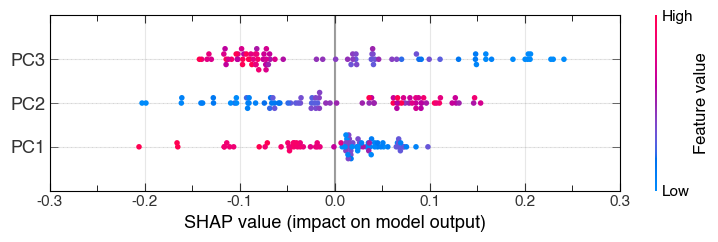

In [92]:
#sns.reset_orig()
#mpl.rcParams['legend.frameon'] = False
#mpl.rcParams['font.size'] = 16
#mpl.rcParams['font.sans-serif'] = 'Helvetica'
#plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8,4))


shap.summary_plot(
    shap_values[:, :, class_idx_i],  
    X_train_new.values,
    feature_names=X_train_new.columns,
    show=False
)

# get current axis
ax = plt.gca()


# major ticks (inside, on all sides)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, left = True, length=6)
# minor ticks
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, left = True, length=4)


# Set tick intervals
ax.xaxis.set_major_locator(plt.MultipleLocator(0.1))  
ax.xaxis.set_minor_locator(plt.MultipleLocator(0.05)) 

# borders
for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_visible(True)

plt.xlim(-0.3, 0.3)
plt.grid(True, alpha=0.3)
# Tight layout to avoid clipping
plt.tight_layout()
#plt.savefig('/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/SVC/SVC_SHAP/shap_beeswarm_class_i.png', dpi = 600)
plt.show()

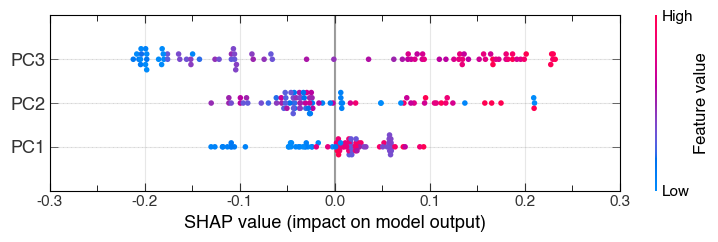

In [93]:
sns.reset_orig()
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8,4))


shap.summary_plot(
    shap_values[:, :, class_idx_p],  
    X_train_new.values,
    feature_names=X_train_new.columns,
    show=False
)

# get current axis
ax = plt.gca()


# major ticks (inside, on all sides)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, left = True, length=6)
# minor ticks
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, left = True, length=4)


# Set tick intervals
ax.xaxis.set_major_locator(plt.MultipleLocator(0.1))  
ax.xaxis.set_minor_locator(plt.MultipleLocator(0.05)) 

# === Add Borders ===
for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_visible(True)

plt.xlim(-0.3, 0.3)
# Tight layout to avoid clipping
plt.grid(True, alpha=0.3)
plt.tight_layout()
#plt.savefig('/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/SVC/SVC_SHAP/shap_beeswarm_class_p.png', dpi = 600)
plt.show()

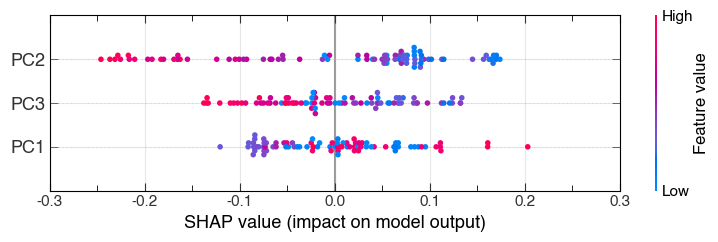

In [94]:
sns.reset_orig()
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8,4))


shap.summary_plot(
    shap_values[:, :, class_idx_n],  
    X_train_new.values,
    feature_names=X_train_new.columns,
    show=False
)

# get current axis
ax = plt.gca()


# major ticks (inside, on all sides)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, left = True, length=6)
# minor ticks
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, left = True, length=4)


# Set tick intervals
ax.xaxis.set_major_locator(plt.MultipleLocator(0.1))  
ax.xaxis.set_minor_locator(plt.MultipleLocator(0.05)) 

# === Add Borders ===
for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_visible(True)

plt.xlim(-0.3, 0.3)
# Tight layout to avoid clipping
plt.grid(True, alpha=0.3)
plt.tight_layout()
#plt.savefig('/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/SVC/SVC_SHAP/shap_beeswarm_class_n.png', dpi = 600)
plt.show()

### Per sample SHAP

In [95]:
def _ensure_dir(path: str):
    os.makedirs(path, exist_ok=True)

def _get_feature_names(X) -> List[str]:
    if hasattr(X, "columns"):
        return list(X.columns)
    return [f"f{j}" for j in range(X.shape[1])]

def shap_per_sample_svc(
    model,                
    X_train,             
    X_test,              
    struc_list,
    output_root="./output_svc_simple"
):
    _ensure_dir(output_root)
    feat_names = _get_feature_names(X_test)
    X_test_arr = X_test.values if hasattr(X_test, "values") else np.asarray(X_test)
    n_samples = X_test_arr.shape[0]
    
    # identify classes
    class_labels = best_model.classes_
    n_classes = len(class_labels)

    # background Summary (Crucial for SVC speed)
    # using 10 centroids to represent the distribution of training data
    # background = shap.kmeans(X_train, 10)

    # initialize KernelExplainer
    explainer = shap.KernelExplainer(best_model.predict_proba, X_train)

    # calculate SHAP values per class
    print("Calculating SHAP values for SVC (this may take a moment)...")
    shap_values_output = explainer.shap_values(X_test_arr)

    if isinstance(shap_values_output, list):
        shap_values_list = shap_values_output
    else:
        # If it returned a single 3D array (n_samples, n_features, n_classes)
        if shap_values_output.ndim == 3:
            shap_values_list = [shap_values_output[:,:,c] for c in range(n_classes)]
        # If it returned a 2D array for binary classification
        else:
            shap_values_list = [1 - shap_values_output, shap_values_output]  

    # plot per Class
    for c_idx in range(n_classes):
        cdir = os.path.join(output_root, f"Class_{c_idx}")
        _ensure_dir(cdir)
        
        # SHAP array for this specific class: (n_samples, n_features)
        class_shap = shap_values_list[c_idx]

        for i in range(n_samples):
            si = struc_list[i]
            sample_shap = class_shap[i]

            # Save CSV
            df_out = pd.DataFrame({
                "Feature": feat_names,
                "SHAP_Value": sample_shap
            })
            df_out.to_csv(os.path.join(cdir, f"SVC_SHAP_struc{si}.csv"), index=False)

            # Plotting (Single bar chart, no error bars)
            order = np.argsort(np.abs(sample_shap))
            plt.figure(figsize=(7, max(4, len(feat_names) * 0.3)))
            plt.barh(np.array(feat_names)[order], sample_shap[order], color='cornflowerblue')

            plt.gca().spines["top"].set_visible(False)
            plt.gca().spines["right"].set_visible(False)
            
            plt.xlabel("SHAP Value (Impact on Model Output)")
            plt.title(f"SVC: Structure {si} - Class {class_labels[c_idx]}")
            plt.axvline(0, color='black', lw=0.8) # Reference line at zero
            plt.tight_layout()
            
            #plt.savefig(os.path.join(cdir, f"SVC_SHAP_Plot_struc{si}.png"), dpi=600)
            plt.close() 

    print(f"Done! Results saved to {output_root}")

In [96]:
shap_per_sample_svc(calibrated_svc, X_train_new, X_test_new, list(test_join.structures),
                                    output_root="/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/SVC/SVC_SHAP")

Calculating SHAP values for SVC (this may take a moment)...


100%|██████████| 20/20 [00:00<00:00, 215.57it/s]


Done! Results saved to /home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/SVC/SVC_SHAP


In [97]:
explainer = shap.KernelExplainer(calibrated_svc.predict_proba, X_train_new) 

# SHAP values (for all classes)
shap_values = explainer.shap_values(X_train_new)
base_values = explainer.expected_value

100%|██████████| 84/84 [00:00<00:00, 227.16it/s]


### Save SHAP data - Training data

In [98]:
if isinstance(shap_values, list):
    # list length = n_classes; each is (n_samples, n_features)
    shap_3d = np.stack(shap_values, axis=-1)
else:
    # already (n_samples, n_features, n_classes)
    shap_3d = shap_values

n_samples, n_features, n_classes = shap_3d.shape
assert n_classes == 3, f"Expected 3 classes, got {n_classes}"

# one SHAP dataframe per class/output
shap_dfs = {}
for k in range(3):
    df_k = pd.DataFrame(shap_3d[:, :, k], columns=X_train_new.columns, index=X_train_new.index)
    #optionally add base value and model output being explained
    df_k["base_value"] = base_values[k] if hasattr(base_values, "__len__") else base_values
    #df_k["model_output"] = calibrated_svc.estimator.decision_function(X_train_new)[:, k]
    df_k["model_output"] = calibrated_svc.predict_proba(X_train_new)[:, k]
    shap_dfs[f"class_{k}"] = df_k

In [99]:
class_names = getattr(best_model, "classes_", None)
if class_names is None:
    # fallback names
    class_names = [f"class{k}" for k in range(n_classes)]

In [100]:
out = pd.DataFrame(index=X_train_new.index)

for k, cname in enumerate(class_names):
    dfk = pd.DataFrame(shap_3d[:, :, k],
                       index=X_train_new.index,
                       columns=[f"{col}__SHAP_{cname}" for col in X_train_new.columns])
    out = pd.concat([out, dfk], axis=1)

# optionally store the decision_function outputs per class
#scores = calibrated_svc.estimator.decision_function(X_train_new)  # (n_samples, n_classes)
scores = calibrated_svc.predict_proba(X_train_new) 
scores_df = pd.DataFrame(scores, index=X_train_new.index,
                         columns=[f"probability_{c}" for c in class_names])
out = pd.concat([out, scores_df], axis=1)

# optionally store base/expected values per class (same for every row)
# base_values is length = n_classes for multiclass outputs
for k, cname in enumerate(class_names):
    out[f"base_value_{cname}"] = base_values[k] if hasattr(base_values, "__len__") else base_values

# Save
#out.to_csv("shap_dataframe_wide_v3.csv", index=True)

In [101]:
#shap_df_class0 = shap_dfs["class_0"]
#shap_df_class1 = shap_dfs["class_1"]
#shap_df_class2 = shap_dfs["class_2"]

In [102]:
df = pd.read_csv("shap_dataframe_wide_v3.csv", index_col=0)

classes = ["i", "n", "p"] 
feat_names = ["PC1", "PC2", "PC3"]  

# predicted class per row using decision_function outputs
dec = df[[f"probability_{c}" for c in classes]].to_numpy()
pred_idx = dec.argmax(axis=1)  
pred_class = [classes[k] for k in pred_idx]
df["pred_class"] = calibrated_svc.predict(X_train_new)

# build a single SHAP matrix: for each row, take SHAP columns of its predicted class
#X_shap = np.zeros((len(df), len(feat_names)))
#for r, c in enumerate(pred_class):
#    X_shap[r, :] = df[[f"{f}__SHAP_{c}" for f in feat_names]].iloc[r].to_numpy()

#X_shap_df = pd.DataFrame(X_shap, index=df.index, columns=feat_names)


X_shap_df = df.drop(columns=['decision_i', 'decision_n', 'decision_p',	'base_value_i',	'base_value_n',	'base_value_p',	'pred_class'])

In [103]:
X_shap_df = df.filter(regex=r"^PC")

In [104]:
X_shap_df

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695
...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184


### Plot clusters

In [4]:
df = pd.read_csv('/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/shap_dataframe_wide_v3.csv')

In [5]:
X_shap_df = df.filter(regex=r"^PC")

In [6]:
X_shap_df

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695
...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184


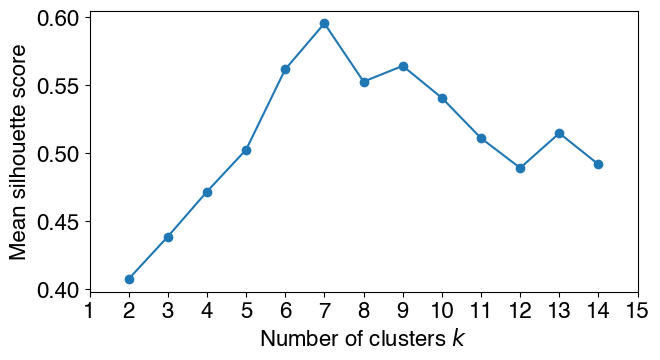

In [9]:
from matplotlib.ticker import MaxNLocator
#sns.set_theme()
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 20
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False

k_range = range(2, 15)  
#inertias = []
sil_scores = []

#for k in k_range:
#    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
#    km.fit(X_shap_df)
#    inertias.append(km.inertia_)  # total within-cluster sum of squares

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=500) #KMeans(n_clusters=k, random_state=42, n_init="auto", max_iter = 1000)
    labels = km.fit_predict(X_shap_df)
    sil_scores.append(silhouette_score(X_shap_df, labels))

plt.figure(figsize=(7, 4))
plt.plot(list(k_range), sil_scores, marker="o")

plt.xlabel("Number of clusters $k$", fontsize=16)
plt.ylabel("Mean silhouette score", fontsize=16)

plt.xlim(1, 14)
plt.xticks(range(1, 16), fontsize=16)   # 1, 2, 3, ...
plt.yticks(fontsize=16)

plt.tight_layout()
plt.savefig("k_means_v_fin.pdf", dpi=600, bbox_inches="tight")
plt.show()

In [107]:
sil_score = pd.DataFrame({
    'sil_scores': sil_scores,
    'k': list(k_range)
})

In [108]:
sil_score

,sil_scores,k
0,0.407519,2
1,0.438659,3
2,0.471791,4
3,0.502638,5
4,0.561835,6
5,0.595569,7
6,0.552708,8
7,0.564278,9
8,0.540734,10
9,0.511112,11


In [109]:
sil_score = pd.DataFrame((sil_scores, list(k_range)))
sil_score

# k-means
k = 7
#X_scaled = StandardScaler().fit_transform(X_shap_df)  
km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=500)
clusters = km.fit_predict(X_shap_df)

# cluster_info: original rows + cluster label
cluster_info = df.copy()
cluster_info = cluster_info.drop(columns=['probability_i', 'probability_n', 'probability_p', 'base_value_i', 'base_value_n', 'base_value_p'])
cluster_info["cluster"] = clusters +1


cluster_info['structures'] = train_join.structures
#cluster_info['defect_type'] = defect_type
cluster_info['true_class'] = train_join.carrier_type

cluster_info.to_csv("cluster_info_predclass_shap.csv")

In [112]:
cluster_info_train = cluster_info
cluster_info.to_csv("cluster_info_predclass_shap_v2.csv")

In [111]:
cluster_info_train

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p,pred_class,cluster,structures,true_class
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228,p,1,2,p
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499,i,6,3,i
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491,i,6,4,p
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575,n,2,5,n
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695,p,5,6,p
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524,p,1,111,p
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632,n,7,112,n
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660,p,1,114,p
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184,n,7,117,n


### Save SHAP data - Test data

In [113]:
#explainer = shap.KernelExplainer(calibrated_svc.predict_proba, X_train_new) 

# SHAP values (for all classes)
shap_values_test = explainer.shap_values(X_test_new)
base_values_test = explainer.expected_value

100%|██████████| 20/20 [00:00<00:00, 178.29it/s]


In [114]:
if isinstance(shap_values_test, list):
    # list length = n_classes; each is (n_samples, n_features)
    shap_3d_test = np.stack(shap_values_test, axis=-1)
else:
    # already (n_samples, n_features, n_classes)
    shap_3d_test = shap_values_test

n_samples, n_features, n_classes = shap_3d_test.shape
assert n_classes == 3, f"Expected 3 classes, got {n_classes}"

# one SHAP dataframe per class/output
shap_dfs_test = {}
for k in range(3):
    df_k = pd.DataFrame(shap_3d_test[:, :, k], columns=X_test_new.columns, index=X_test_new.index)
    #optionally add base value and model output being explained
    df_k["base_value"] = base_values_test[k] if hasattr(base_values_test, "__len__") else base_values
    df_k["model_output"] = calibrated_svc.predict_proba(X_test_new)[:, k]
    shap_dfs_test[f"class_{k}"] = df_k

In [115]:
class_names = getattr(calibrated_svc, "classes_", None)
if class_names is None:
    # fallback names
    class_names = [f"class{k}" for k in range(n_classes)]

In [116]:
out = pd.DataFrame(index=X_test_new.index)

for k, cname in enumerate(class_names):
    dfk = pd.DataFrame(shap_3d_test[:, :, k],
                       index=X_test_new.index,
                       columns=[f"{col}__SHAP_{cname}" for col in X_test_new.columns])
    out = pd.concat([out, dfk], axis=1)

# optionally store the decision_function outputs per class
scores = calibrated_svc.predict_proba(X_test_new)  # (n_samples, n_classes)
scores_df = pd.DataFrame(scores, index=X_test_new.index,
                         columns=[f"decision_{c}" for c in class_names])
out = pd.concat([out, scores_df], axis=1)

# optionally store base/expected values per class (same for every row)
# base_values is length = n_classes for multiclass outputs
for k, cname in enumerate(class_names):
    out[f"base_value_{cname}"] = base_values_test[k] if hasattr(base_values_test, "__len__") else base_values_test

# Save
out.to_csv("shap_test_dataframe_wide.csv", index=True)

In [117]:
X_shap_df_test = out

In [118]:
out

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p,decision_i,decision_n,decision_p,base_value_i,base_value_n,base_value_p
0,-0.042399,0.115768,0.164111,0.037023,-0.093582,0.045366,0.005375,-0.022186,-0.209477,0.503418,0.210150,0.286433,0.265937,0.221343,0.512721
1,-0.036478,-0.040518,-0.081172,-0.024732,0.084477,-0.106349,0.061210,-0.043958,0.187521,0.107768,0.174738,0.717493,0.265937,0.221343,0.512721
2,0.027309,0.061298,-0.081468,0.018402,-0.224855,0.003807,-0.045711,0.163557,0.077661,0.273076,0.018696,0.708228,0.265937,0.221343,0.512721
3,0.029731,0.087801,-0.130224,-0.053569,-0.104384,-0.042976,0.023838,0.016583,0.173200,0.253245,0.020414,0.726342,0.265937,0.221343,0.512721
4,-0.206383,0.063113,0.089154,0.202860,-0.004600,0.120894,0.003522,-0.058513,-0.210049,0.211821,0.540498,0.247681,0.265937,0.221343,0.512721
5,-0.044096,0.114002,0.167225,0.039153,-0.091323,0.041527,0.004944,-0.022678,-0.208752,0.503067,0.210699,0.286234,0.265937,0.221343,0.512721
6,0.023092,-0.091004,0.017176,-0.042839,0.188789,0.157581,0.019747,-0.097785,-0.174758,0.215201,0.524874,0.259925,0.265937,0.221343,0.512721
7,0.006865,-0.093458,-0.070871,-0.088394,0.078336,-0.038177,0.081529,0.015123,0.109048,0.108472,0.173107,0.718421,0.265937,0.221343,0.512721
8,-0.079556,-0.004968,-0.074437,0.007269,0.041991,-0.077533,0.072287,-0.037024,0.151970,0.106976,0.193070,0.699954,0.265937,0.221343,0.512721
9,-0.038737,-0.046740,-0.072886,-0.049781,0.090739,-0.069527,0.088518,-0.043999,0.142413,0.107573,0.192774,0.699653,0.265937,0.221343,0.512721


In [119]:
X_shap_df_test_v2 = X_shap_df_test.copy()

In [120]:
X_shap_df_test_v2 = X_shap_df_test_v2.filter(regex=r"^PC")

In [121]:
X_shap_df

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695
...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184


In [122]:
km = KMeans(n_clusters=7, random_state=42, n_init=10, max_iter=500)
km.fit(X_shap_df)
labels = km.predict(X_shap_df_test_v2)

In [123]:
silhouette_score(X_shap_df_test, labels)

0.5261560542299873

In [124]:
labels

array([2, 0, 3, 3, 1, 2, 6, 0, 0, 0, 0, 6, 3, 2, 0, 6, 6, 6, 6, 0],
      dtype=int32)

In [125]:
# cluster_info: original rows + cluster label
cluster_info = X_shap_df_test_v2.copy()
#cluster_info = cluster_info.drop(columns=['decision_i', 'decision_n', 'decision_p', 'base_value_i', 'base_value_n', 'base_value_p'])
cluster_info["cluster"] = labels +1


cluster_info['structures'] = test_join.structures
#cluster_info['defect_type'] = defect_type
cluster_info['true_class'] = test_join.carrier_type

cluster_info.to_csv("cluster_info_predclass_shap_test.csv")

In [126]:
cluster_info

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p,cluster,structures,true_class
0,-0.042399,0.115768,0.164111,0.037023,-0.093582,0.045366,0.005375,-0.022186,-0.209477,3,10,i
1,-0.036478,-0.040518,-0.081172,-0.024732,0.084477,-0.106349,0.061210,-0.043958,0.187521,1,11,p
2,0.027309,0.061298,-0.081468,0.018402,-0.224855,0.003807,-0.045711,0.163557,0.077661,4,16,i
3,0.029731,0.087801,-0.130224,-0.053569,-0.104384,-0.042976,0.023838,0.016583,0.173200,4,21,p
4,-0.206383,0.063113,0.089154,0.202860,-0.004600,0.120894,0.003522,-0.058513,-0.210049,2,31,i
5,-0.044096,0.114002,0.167225,0.039153,-0.091323,0.041527,0.004944,-0.022678,-0.208752,3,38,i
6,0.023092,-0.091004,0.017176,-0.042839,0.188789,0.157581,0.019747,-0.097785,-0.174758,7,40,n
7,0.006865,-0.093458,-0.070871,-0.088394,0.078336,-0.038177,0.081529,0.015123,0.109048,1,49,p
8,-0.079556,-0.004968,-0.074437,0.007269,0.041991,-0.077533,0.072287,-0.037024,0.151970,1,52,p
9,-0.038737,-0.046740,-0.072886,-0.049781,0.090739,-0.069527,0.088518,-0.043999,0.142413,1,53,p


### Prepare data for plotting

In [127]:
# orig = pd.read_csv("PCA_with_Defect_Types.csv")  # has 'structures'
# cluster_info = cluster_info.merge(orig[['structures']], left_index=True, right_index=True, how='left')

df_new = cluster_info_train.copy()

# Safety
df_new = df_new.dropna(subset=["cluster", "structures"])
df_new["cluster"] = df_new["cluster"].astype(int)
df_new["structures"] = df_new["structures"].astype(int)

clusters = sorted(df_new["cluster"].unique())
n = len(clusters)

# layout similar to the paper (2 rows of 5 when k=10, etc.)
ncols = 5 if n >= 5 else n
nrows = math.ceil(n / ncols)

# bins for integer counts (centers on integers)
xmin, xmax = df_new["structures"].min(), df_new["structures"].max()
bins = np.arange(xmin - 0.5, xmax + 1.5, 1)


In [128]:
#sns.set_theme()
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 20
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False


df_new_2 = cluster_info_train.copy()  
#df_new_2 = df_new_2.dropna(subset=["cluster", "pred_class"])
df_new_2["cluster"] = df_new_2["cluster"].astype(int)

clusters = sorted(df_new_2["cluster"].unique())
categories = ["i", "n", "p"]   

n = len(clusters)
ncols = 4                          #if n >= 5 else n
nrows = math.ceil(n / ncols)

In [129]:
df_new_2

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p,pred_class,cluster,structures,true_class
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228,p,1,2,p
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499,i,6,3,i
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491,i,6,4,p
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575,n,2,5,n
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695,p,5,6,p
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524,p,1,111,p
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632,n,7,112,n
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660,p,1,114,p
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184,n,7,117,n


In [130]:
df_new_2 = df_new_2.merge(
    df_org[['structures', 'Defect_Type']],
    on='structures',
    how='left'   
)

In [131]:
df_new_2

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p,pred_class,cluster,structures,true_class,Defect_Type
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228,p,1,2,p,V$_{Bi} - 5 \%$
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499,i,6,3,i,V$_{Te1} - 5 \%$
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491,i,6,4,p,V$_{Te2} - 15 \%$
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575,n,2,5,n,A$_{Te@Bi} - 5 \%$
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695,p,5,6,p,A$_{Bi@Te2} - 10 \%$
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524,p,1,111,p,A$_{Bi@Te1} - 20 \%$
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632,n,7,112,n,A$_{Te@Bi} - 20 \%$
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660,p,1,114,p,A$_{Bi@Te1} - 20 \%$
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184,n,7,117,n,A$_{Te@Bi} - 20 \%$


In [132]:
#sns.reset_orig()

#mpl.rcParams['legend.frameon'] = False
#mpl.rcParams['font.size'] = 16
#mpl.rcParams['font.sans-serif'] = 'Helvetica'
#plt.rcParams['axes.unicode_minus'] = False

df_new_3 = df_new_2.copy()

# clean types
#df_new_3["cluster"] = df_new_3["cluster"].astype(int)
#df_new_3["true_class"] = df_new_3["true_class"]                            #df_new_3["true_class"].astype(str)
#df_new_3["Defect_Type"] = df_new_3["Defect_Type"]                                 #df_new_3["defect_type"].astype(str)

# Dominant carrier type per cluster
# if ties happen, this picks the first in sorted order
#dom_carrier = (
#    df_new_3.groupby("cluster")["pred_class"]
#      .agg(lambda s: s.value_counts().idxmax())
#)

# cluster_n.carrier_type
#title_map = {c: f"Cluster_{c}.{dom_carrier.loc[c]}" for c in dom_carrier.index}

#cluster_order = sorted(title_map.keys())
#df_new_3["cluster_title"] = df_new_3["cluster"].map(title_map)

# defect_type counts per cluster
#g = sns.catplot(
#    data=df_new_3,
#    x="Defect_Type",
#    kind="count",
#    col="cluster_title",
#    col_order=[title_map[c] for c in cluster_order],  
#    col_wrap=2,               
#    color="red",
#    height=3.0,
#    aspect=1.8                
#)

#g.set_axis_labels("Defect_Type", "count")
#g.set_titles("{col_name}")


#for ax in g.axes.flatten():
#    ax.tick_params(axis="both", labelrotation=90, labelsize=14) 
#    ax.set_ylim(0, 10)

#plt.tight_layout()
#plt.savefig("cluster_carrier_type_counts_fin.png", dpi=600)
#plt.show()

In [133]:
base_map = {
    r"V$_{Bi}": r"$V_{Bi}$",
    r"V$_{Te1}": r"$V_{Te1}$",
    r"V$_{Te2}": r"$V_{Te2}$",
    r"A$_{Bi@Te1}": r"$A_{Bi_{Te1}}$",
    r"A$_{Te@Bi}": r"$A_{Te_{Bi}}$",
    r"A$_{Bi@Te2}": r"$A_{Bi_{Te2}}$",
}

def normalize_defect_type(s):
    if pd.isna(s):
        return s

    s = str(s).strip()

    # Match: defect part  -  number  \%  optional trailing $
    m = re.match(r"^(.*?)\s*-\s*([0-9]+)\s*\\%\$?$", s)
    if m:
        defect, pct = m.groups()
        defect = defect.strip()
        defect_norm = base_map.get(defect, defect)
        return f"{defect_norm} - {pct}%"

    return base_map.get(s, s)

df_new_3["Defect_Type_norm"] = df_new_3["Defect_Type"].apply(normalize_defect_type)


In [134]:
df_new_3

,PC1__SHAP_i,PC2__SHAP_i,PC3__SHAP_i,PC1__SHAP_n,PC2__SHAP_n,PC3__SHAP_n,PC1__SHAP_p,PC2__SHAP_p,PC3__SHAP_p,pred_class,cluster,structures,true_class,Defect_Type,Defect_Type_norm
0,0.019064,-0.074106,-0.102054,-0.074287,0.101803,-0.062174,0.055223,-0.027696,0.164228,p,1,2,p,V$_{Bi} - 5 \%$,$V_{Bi}$ - 5%
1,0.098176,-0.066311,0.203876,-0.120666,0.089857,0.004623,0.022490,-0.023546,-0.208499,i,6,3,i,V$_{Te1} - 5 \%$,$V_{Te1}$ - 5%
2,0.064811,-0.049124,0.241417,-0.080028,0.091296,-0.055926,0.015217,-0.042172,-0.185491,i,6,4,p,V$_{Te2} - 15 \%$,$V_{Te2}$ - 15%
3,-0.106417,-0.035472,0.088707,0.091482,0.112815,0.114869,0.014934,-0.077342,-0.203575,n,2,5,n,A$_{Te@Bi} - 5 \%$,$A_{Te_{Bi}}$ - 5%
4,0.026776,-0.198802,0.017236,-0.085593,-0.010758,0.048459,0.058816,0.209561,-0.065695,p,5,6,p,A$_{Bi@Te2} - 10 \%$,$A_{Bi_{Te2}}$ - 10%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,-0.047608,-0.015894,-0.093100,0.025028,0.051981,-0.134423,0.022580,-0.036086,0.227524,p,1,111,p,A$_{Bi@Te1} - 20 \%$,$A_{Bi_{Te1}}$ - 20%
80,0.055895,-0.036131,-0.068013,0.062361,0.145117,0.097645,-0.118256,-0.108987,-0.029632,n,7,112,n,A$_{Te@Bi} - 20 \%$,$A_{Te_{Bi}}$ - 20%
81,0.011730,-0.063425,-0.103771,-0.044527,0.068031,-0.097889,0.032796,-0.004606,0.201660,p,1,114,p,A$_{Bi@Te1} - 20 \%$,$A_{Bi_{Te1}}$ - 20%
82,0.048622,-0.105251,0.000974,0.064376,0.166783,0.086210,-0.112998,-0.061532,-0.087184,n,7,117,n,A$_{Te@Bi} - 20 \%$,$A_{Te_{Bi}}$ - 20%


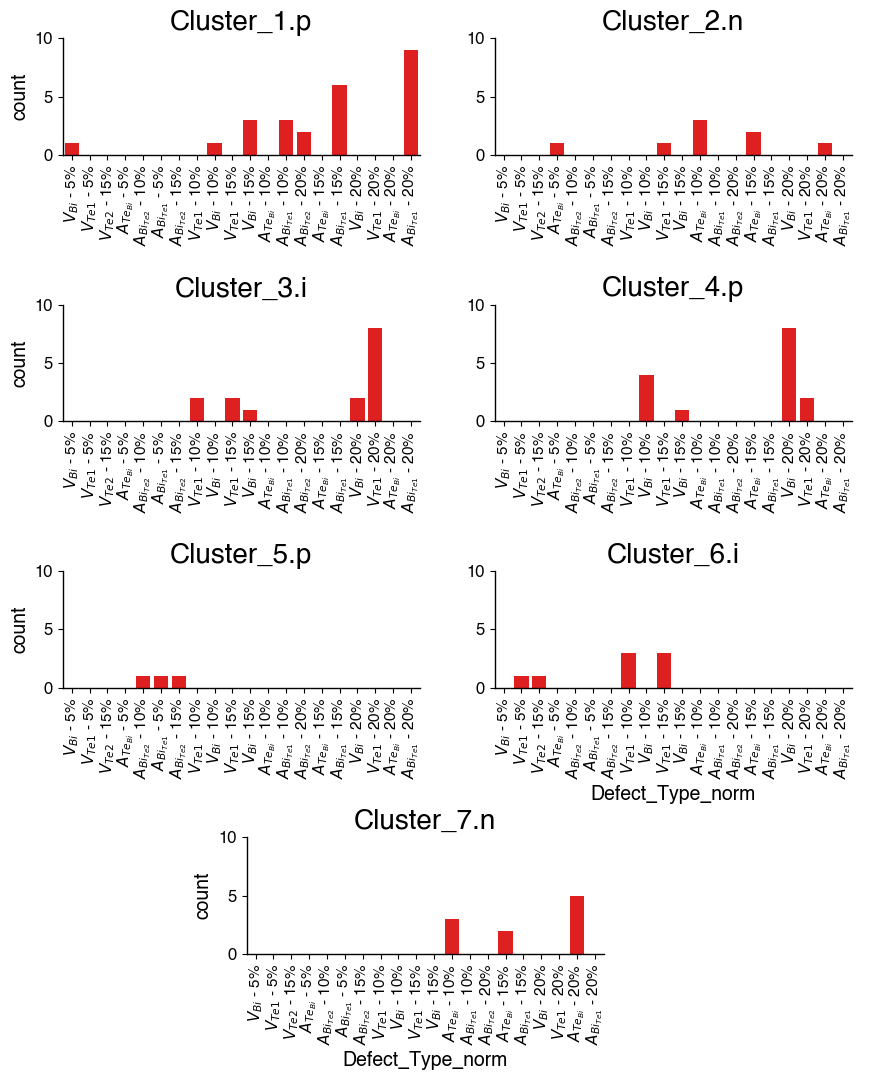

In [135]:
dom_carrier = (
    df_new_3.groupby("cluster")["pred_class"]
      .agg(lambda s: s.value_counts().idxmax())
)

title_map = {c: f"Cluster_{c}.{dom_carrier.loc[c]}" for c in dom_carrier.index}
cluster_order = sorted(title_map.keys())
df_new_3["cluster_title"] = df_new_3["cluster"].map(title_map)

# fixed order of all defect types across all facets
defect_order = list(df_new_3["Defect_Type_norm"].dropna().unique())

g = sns.catplot(
    data=df_new_3,
    x="Defect_Type_norm",
    kind="count",
    col="cluster_title",
    col_order=[title_map[c] for c in cluster_order],
    col_wrap=2,
    order=defect_order,
    color="red",
    height=2.8,
    aspect=1.6,
    sharex=False,   # important
    sharey=False
)

g.set_axis_labels("Defect_Type_norm", "count", fontsize=14)
g.set_titles("{col_name}")

for ax in g.axes.flatten():
    ax.set_ylim(0, 10)
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xticklabels(defect_order, rotation=90, ha="center", fontsize=11)
    ax.tick_params(axis="y", labelsize=12)

    for side in ["bottom", "left"]:                                                 #"top", "right", 
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)
        ax.spines[side].set_color("black")

plt.tight_layout()

axes = g.axes.flatten()

if len(axes) % 2 == 1:
    last_ax = axes[-1]

    left_ax = axes[-2]          # left position in the last row
    pos_last = last_ax.get_position()
    pos_left = left_ax.get_position()

    gap = pos_last.x0 - pos_left.x1
    new_x0 = 0.5 - pos_last.width / 2   # center in the figure

    last_ax.set_position([new_x0, pos_last.y0, pos_last.width, pos_last.height])
plt.savefig("cluster_carrier_type_counts_fin_v3.pdf", dpi=600)
plt.show()

In [136]:
df_new_2.to_csv('cluster_info_predclass_shap_3.csv', index=False)

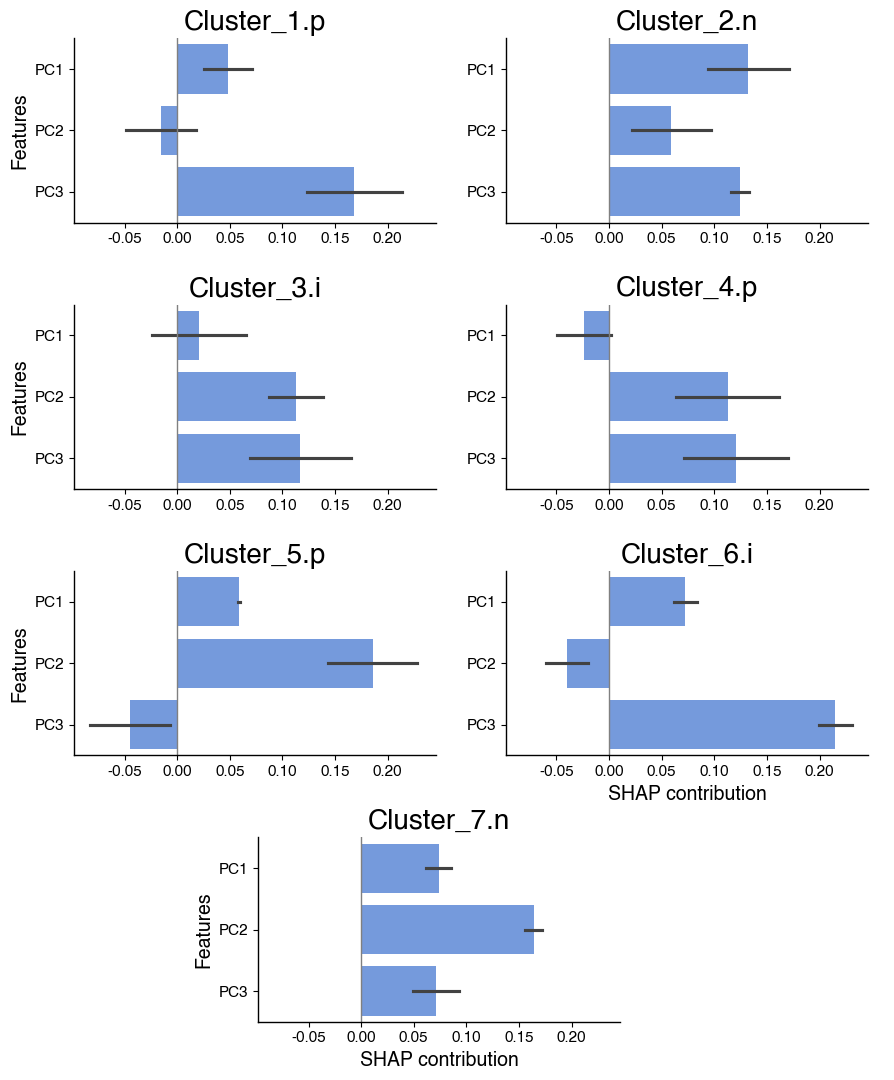

In [137]:
# dominant class per cluster
dom_carrier = (
    df_new_2.groupby("cluster")["pred_class"]
      .agg(lambda s: s.value_counts().idxmax())
)

title_map = {c: f"Cluster_{c}.{dom_carrier.loc[c]}" for c in dom_carrier.index}
cluster_order = sorted(title_map.keys())
df_new_2["cluster_title"] = df_new_2["cluster"].map(title_map)

# wide
shap_cols = [c for c in df_new_2.columns if "__SHAP_" in c]

df_long = df_new_2.melt(
    id_vars=["cluster", "cluster_title", "pred_class", "true_class", "Defect_Type", "structures"],
    value_vars=shap_cols,
    var_name="feature_class",
    value_name="shap_value"
)

# split "PC1__SHAP_p" to feature="PC1", shap_class="p"
tmp = df_long["feature_class"].str.extract(r"^(PC\d+)__SHAP_([inp])$")
df_long["feature"] = tmp[0]
df_long["shap_class"] = tmp[1]

# keep only SHAP columns matching dominant class of that cluster
df_long["dom_class"] = df_long["cluster"].map(dom_carrier)
df_plot = df_long[df_long["shap_class"] == df_long["dom_class"]].copy()

feature_order = ["PC1", "PC2", "PC3"]

g = sns.catplot(
    data=df_plot,
    y="feature",
    x="shap_value",
    kind="bar",
    col="cluster_title",
    col_order=[title_map[c] for c in cluster_order],
    col_wrap=2,
    order=feature_order,
    estimator="mean",
    errorbar="sd",      
    color="cornflowerblue",
    height=2.8,
    aspect=1.6,
  #  sharex=True,
  #  sharey=True,
    orient="h"
)

g.set_axis_labels("SHAP contribution", "Features", fontsize = 14)
g.set_titles("{col_name}")

for ax in g.axes.flatten():
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.axvline(0, color="gray", lw=1)
    ax.tick_params(axis="x", labelbottom=True, labelsize=11)
    ax.tick_params(axis="y", labelleft=True, labelsize=11)
#    ax.set_xlabel("SHAP contribution", fontsize=14)
#    ax.set_ylabel("Features", fontsize=14)

    for side in ["bottom", "left"]:                                     
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)
        ax.spines[side].set_color("black")

plt.tight_layout()

axes = g.axes.flatten()
if len(axes) % 2 == 1:
    last_ax = axes[-1]
    pos_last = last_ax.get_position()
    new_x0 = 0.5 - pos_last.width / 2
    last_ax.set_position([new_x0, pos_last.y0, pos_last.width, pos_last.height])

plt.savefig("cluster_shap_contribution_per_cluster_v3.pdf", dpi=600, bbox_inches="tight")
plt.show()

### Decision Boundaries

In [131]:
from sklearn.inspection import DecisionBoundaryDisplay

In [139]:
best_model

SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706,
    probability=True, random_state=42)

In [209]:
svc_new = SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706,
    probability=True, random_state=42)

svc_new.fit(X_fit, y_fit)

calib_svc_new = CalibratedClassifierCV(
    estimator= svc_new,  
    method="sigmoid",
    cv="prefit"
)

In [210]:
calib_svc_new.fit(X_calib,y_calib)

CalibratedClassifierCV(cv='prefit',
                       estimator=SVC(C=10.0, class_weight='balanced',
                                     gamma=0.06398100414211706,
                                     probability=True, random_state=42))

In [211]:
y_test_pred_calibrated=calib_svc_new.predict(X_test_new)
y_train_pred_calibrated=calib_svc_new.predict(X_train_new)

In [252]:
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap

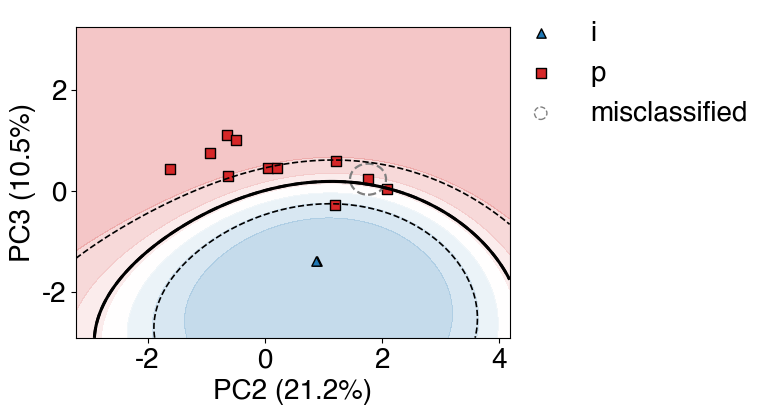

In [257]:
label_i, label_p = "i", "p"

# filter i vs p
m_train = np.isin(y_train, [label_i, label_p])
m_test  = np.isin(y_test_pred_calibrated,  [label_i, label_p])

# keep only PC2 and PC3 from train12.00
cols = [1, 2] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC2", "PC3"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "i_to_p", ["tab:blue", "white", "tab:red"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_i: "^", label_p: "s"}  
color_map  = {label_i: "tab:blue", label_p: "tab:red"}

for lab in [label_i, label_p]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    16:  "p",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC2", "PC3"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC2 (21.2%)")
ax.set_ylabel("PC3 (10.5%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC2_PC3_ivsp.png', dpi=600)
plt.show()

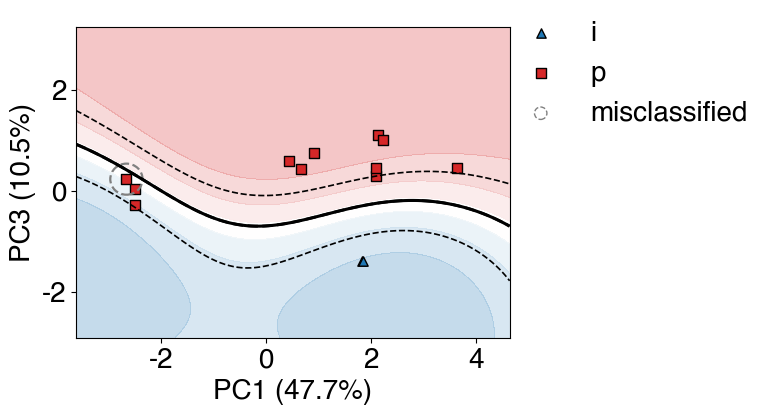

In [256]:
label_i, label_p = "i", "p"

# filter i vs p
m_train = np.isin(y_train, [label_i, label_p])
m_test  = np.isin(y_test_pred_calibrated,  [label_i, label_p])

# keep only PC2 and PC3 from train12.00
cols = [0, 2] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC1", "PC3"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "i_to_p", ["tab:blue", "white", "tab:red"]
)

# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_i: "^", label_p: "s"}  
color_map  = {label_i: "tab:blue", label_p: "tab:red"}

for lab in [label_i, label_p]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    16:  "p",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC1", "PC3"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC1 (47.7%)")
ax.set_ylabel("PC3 (10.5%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC1_PC3_ivsp.png', dpi=600)
plt.show()

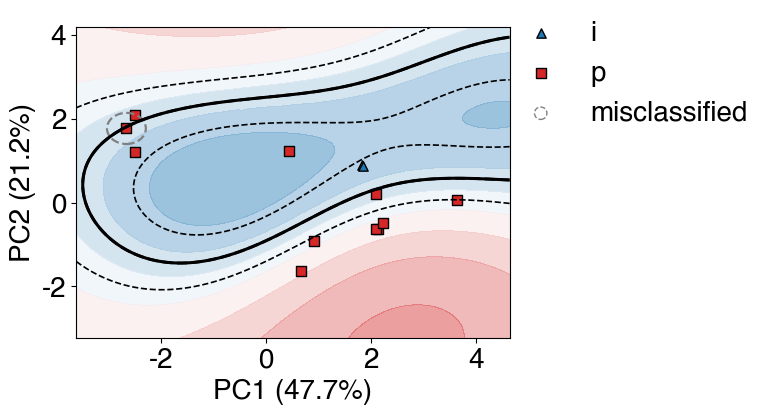

In [254]:
label_i, label_p = "i", "p"

# filter i vs p
m_train = np.isin(y_train, [label_i, label_p])
m_test  = np.isin(y_test_pred_calibrated,  [label_i, label_p])

# keep only PC2 and PC3 from train12.00
cols = [0, 1] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC1", "PC2"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)



cmap_prob = LinearSegmentedColormap.from_list(
    "i_to_p", ["tab:blue", "white", "tab:red"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap= cmap_prob,                                                #plt.cm.Paired,
    alpha=0.50,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_i: "^", label_p: "s"}  
color_map  = {label_i: "tab:blue", label_p: "tab:red"}

for lab in [label_i, label_p]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    16:  "p",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC1", "PC2"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC1 (47.7%)")
ax.set_ylabel("PC2 (21.2%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC1_PC2_ivsp.png', dpi=600)
plt.show()

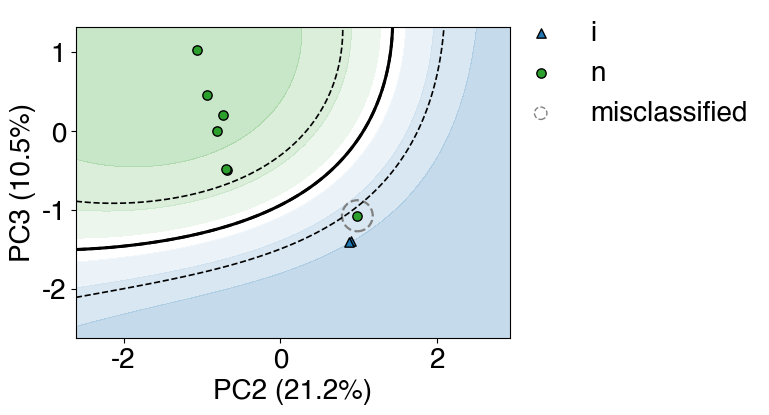

In [269]:
label_i, label_n = "i", "n"

# filter i vs n
m_train = np.isin(y_train, [label_i, label_n])
m_test  = np.isin(y_test_pred_calibrated,  [label_i, label_n])

# keep only PC2 and PC3 from train12.00
cols = [1, 2] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC2", "PC3"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "i_to_n", ["tab:blue", "white", "tab:green"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_i: "^", label_n: "o"}  
color_map  = {label_i: "tab:blue", label_n: "tab:green"}

for lab in [label_i, label_n]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    31:  "n",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC2", "PC3"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC2 (21.2%)")
ax.set_ylabel("PC3 (10.5%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC2_PC3_ivsn.png', dpi=600)
plt.show()

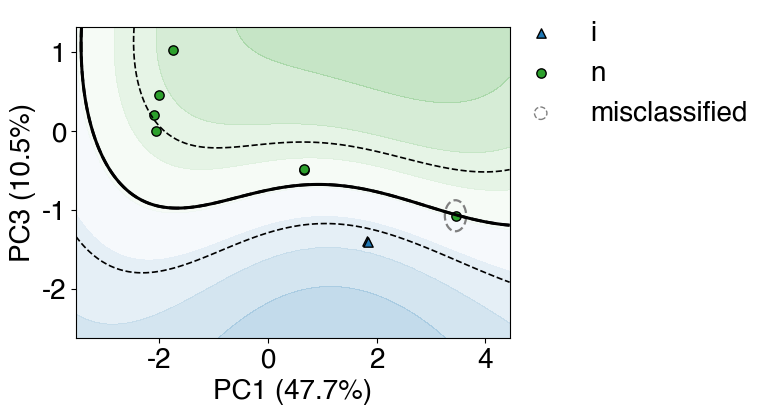

In [270]:
label_i, label_n = "i", "n"

# filter i vs p
m_train = np.isin(y_train, [label_i, label_n])
m_test  = np.isin(y_test_pred_calibrated,  [label_i, label_n])

# keep only PC2 and PC3 from train12.00
cols = [0, 2] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC1", "PC3"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "i_to_n", ["tab:blue", "white", "tab:green"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_i: "^", label_n: "o"}  
color_map  = {label_i: "tab:blue", label_n: "tab:green"}

for lab in [label_i, label_n]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    31:  "n",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC1", "PC3"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC1 (47.7%)")
ax.set_ylabel("PC3 (10.5%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC1_PC3_ivsn.png', dpi=600)
plt.show()

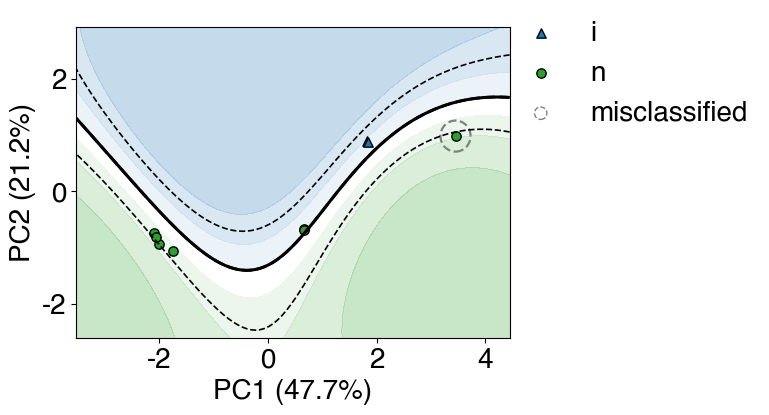

In [266]:
label_i, label_n = "i", "n"

# filter i vs n
m_train = np.isin(y_train, [label_i, label_n])
m_test  = np.isin(y_test_pred_calibrated,  [label_i, label_n])

# keep only PC2 and PC3 from train12.00
cols = [0, 1] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC1", "PC2"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "i_to_n", ["tab:blue", "white", "tab:green"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_i: "^", label_n: "o"}  
color_map  = {label_i: "tab:blue", label_n: "tab:green"}

for lab in [label_i, label_n]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    31:  "n",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC1", "PC2"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC1 (47.7%)")
ax.set_ylabel("PC2 (21.2%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC1_PC2_ivsn.png', dpi=600)
plt.show()

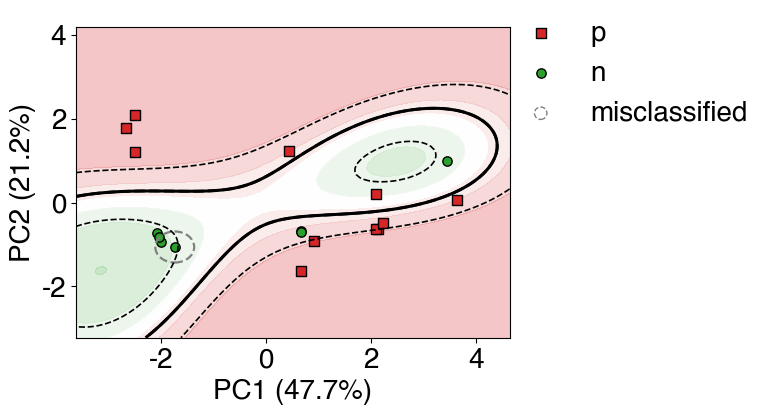

In [279]:
label_p, label_n = "p", "n"

# filter i vs p
m_train = np.isin(y_train, [label_p, label_n])
m_test  = np.isin(y_test_pred_calibrated,  [label_p, label_n])

# keep only PC1 and PC2 from train
cols = [0, 1] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC1", "PC2"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "p_to_n", ["tab:green", "white", "tab:red"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_p: "s", label_n: "o"}  
color_map  = {label_p: "tab:red", label_n: "tab:green"}

for lab in [label_p, label_n]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    103:  "n",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC1", "PC2"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC1 (47.7%)")
ax.set_ylabel("PC2 (21.2%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC1_PC2_pvsn.png', dpi=600)
plt.show()

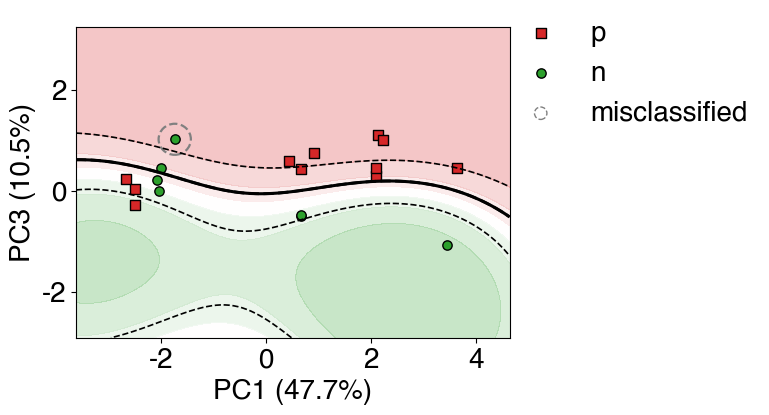

In [280]:
label_p, label_n = "p", "n"

# filter i vs p
m_train = np.isin(y_train, [label_p, label_n])
m_test  = np.isin(y_test_pred_calibrated,  [label_p, label_n])

# keep only PC1 and PC2 from train
cols = [0, 2] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC1", "PC3"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "p_to_n", ["tab:green", "white", "tab:red"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_p: "s", label_n: "o"}  
color_map  = {label_p: "tab:red", label_n: "tab:green"}

for lab in [label_p, label_n]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    103:  "n",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC1", "PC3"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC1 (47.7%)")
ax.set_ylabel("PC3 (10.5%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC1_PC3_pvsn.png', dpi=600)
plt.show()

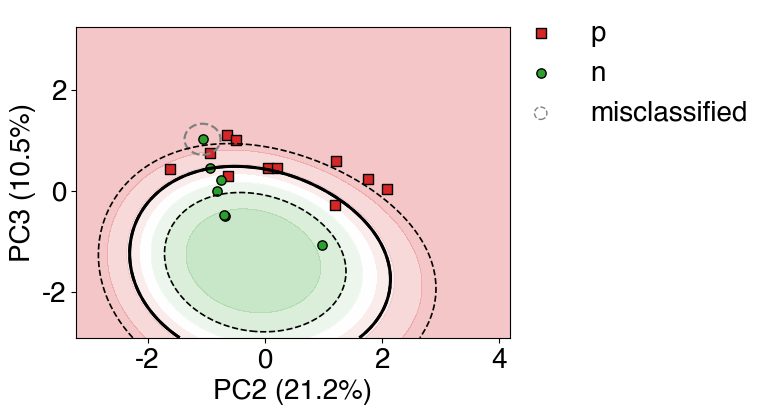

In [281]:
label_p, label_n = "p", "n"

# filter p vs n
m_train = np.isin(y_train, [label_p, label_n])
m_test  = np.isin(y_test_pred_calibrated,  [label_p, label_n])

# keep only PC1 and PC2 from train
cols = [1, 2] 
Xtr = X_train[m_train][:, cols]
ytr = y_train[m_train]


# select PC columns, then pick PC1 and PC3 explicitly
Xte_df = test_join.loc[m_test, :].filter(regex=r"^PC")[["PC2", "PC3"]]
Xte = Xte_df.to_numpy()
yte = y_test_pred_calibrated[m_test]

# fit model on 2D (PC2, PC3)
best_model.fit(Xtr, ytr)

#yte = best_model.predict(Xte)
cmap_prob = LinearSegmentedColormap.from_list(
    "p_to_n", ["tab:green", "white", "tab:red"]
)
# decision regions
fig, ax = plt.subplots(figsize=(8, 4.5))

# Note: "predict_proba" only works if SVC was created with probability=True
# if there is error, switch to response_method="decision_function"
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="predict_proba",
    plot_method="contourf",
    cmap=cmap_prob,
    alpha=0.30,
    ax=ax,
)

# overlay margins (-1, +1) and middle boundary (0)
DecisionBoundaryDisplay.from_estimator(
    best_model,
    Xtr,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.2, 2.2, 1.2],
    ax=ax,
)

# plot f(x)=0 contour (binary boundary)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = best_model.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, Z, levels=[0], colors="k", linestyles="--", linewidths=2)

# plot test points 
marker_map = {label_p: "s", label_n: "o"}  
color_map  = {label_p: "tab:red", label_n: "tab:green"}

for lab in [label_p, label_n]:
    idx = (yte == lab)
    ax.scatter(
        Xte[idx, 0], Xte[idx, 1],
        c=color_map[lab],
        marker=marker_map[lab],
        edgecolor="k",
        s=45,
        label=f"{lab}",
    )

# highlight misclassified samples
mis_label_map = {
    103:  "n",   
}
mis_structures = list(mis_label_map.keys())
X_mis = test_join.loc[
    test_join["structures"].isin(mis_structures), ["PC2", "PC3"]
].to_numpy()
#y_pred = best_model.predict(Xte)
#mis = (y_pred != yte)
#X_mis = Xte[mis]


rx = (xmax - xmin)
ry = (ymax - ymin)
ring_r = 0.05 * min(rx, ry)

for x, y in X_mis:
    ax.add_patch(Circle((x, y), ring_r, fill=False, linestyle="--",
                        linewidth=1.6, edgecolor="grey")) 
    
# include in legend
ax.scatter([], [], facecolors="none", edgecolors="grey", marker="o", linestyle="--",
           s=80, label="misclassified") 

ax.set_xlabel("PC2 (21.2%)")
ax.set_ylabel("PC3 (10.5%)")
#ax.set_title("SVC decision boundary (PC1 vs PC3), i vs p")


ax.legend(loc="center left", bbox_to_anchor=(0.95, 0.85), frameon=False)
fig.tight_layout()
plt.savefig('dec_bndr_PC2_PC3_pvsn.png', dpi=600)
plt.show()

In [276]:
test_join

,PC1,PC2,PC3,structures,carrier_type,pred,p_i,p_n,p_p
0,1.827503,0.897096,-1.390573,10,i,i,0.741168,0.198650,0.060182
1,2.132444,-0.635340,1.104415,11,p,p,0.030456,0.003915,0.965629
2,-2.665997,1.768632,0.225940,16,i,i,0.419143,0.020722,0.560135
3,0.439627,1.222936,0.583518,21,p,p,0.148510,0.045923,0.805568
4,3.451529,0.982238,-1.074355,31,i,i,0.447925,0.456679,0.095396
5,1.837252,0.881876,-1.403496,38,i,i,0.739040,0.201474,0.059486
6,0.668695,-0.680837,-0.495084,40,n,n,0.147661,0.551020,0.301319
7,0.662316,-1.622642,0.419781,49,p,p,0.038169,0.007648,0.954184
8,3.630735,0.064620,0.440594,52,p,p,0.089009,0.071717,0.839274
9,2.083669,-0.631579,0.289159,53,p,p,0.079084,0.080318,0.840598


In [75]:
#plot_3d_rbf_decision_boundary(best_model=best_model, X=X_test, y=y_test)

### PDP plots

In [76]:
X = df_pca.iloc[:,0:3]

In [77]:
X

,PC1,PC2,PC3
0,-0.536303,-1.105306,0.492782
1,-0.763957,-1.388229,-1.468762
2,-0.837809,-0.977521,-1.912788
3,1.972408,-0.371654,-0.937943
4,-0.554138,-2.212283,-0.541010
...,...,...,...
99,-1.942535,-0.364596,0.103168
100,-0.255638,-1.394088,2.238030
101,2.087099,0.207045,0.452741
102,-1.993772,-1.035521,-0.270218


In [312]:
best_model = SVC(C=10.0, gamma=0.06398100414211706, kernel= 'rbf', class_weight="balanced", random_state=42, probability=True)
best_model.fit(X_train, y_train)

SVC(C=10.0, class_weight='balanced', gamma=0.06398100414211706,
    probability=True, random_state=42)

### PDP plots

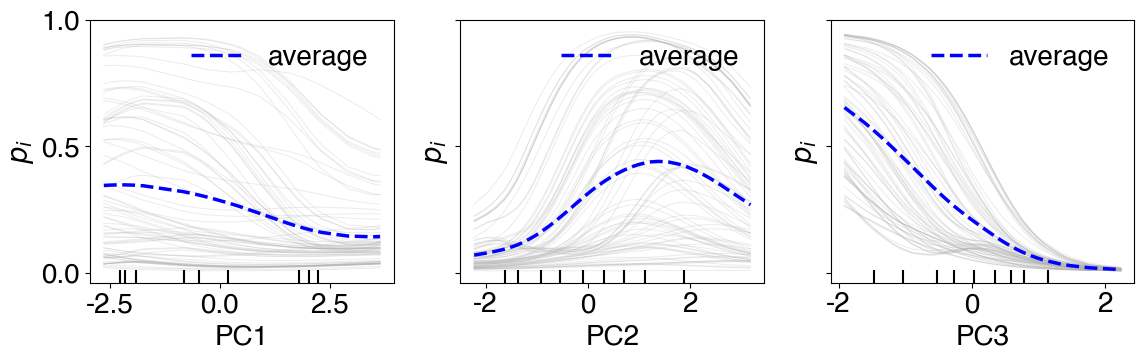

In [324]:
features_1d = [0, 1, 2]

fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

PartialDependenceDisplay.from_estimator(
    best_model, X_train_new, features=features_1d,
    feature_names=["PC1","PC2","PC3"],
    target=best_model.classes_[0],                 # multiclass needs target
    response_method="predict_proba",
    kind="both",                           
    subsample=1000, random_state=42,          
    grid_resolution=400,
    method='brute',
    line_kw={"linewidth": 1.0},             
    ice_lines_kw={"color": "0.7", "alpha": 0.25, "linewidth": 0.7},
    pd_line_kw={"color": "blue", "linewidth": 2.5},
    ax=ax
)

for a in ax:
    a.set_ylabel(r"$p_i$")
    a.legend(loc='upper right')
plt.tight_layout()
plt.savefig('/home/digifort/Pictures/paper_1_figs/upload/pdp_PC1.png', dpi = 600)
plt.savefig('/home/digifort/Pictures/paper_1_figs/upload/pdp_PC1.pdf', dpi = 600)
plt.show()



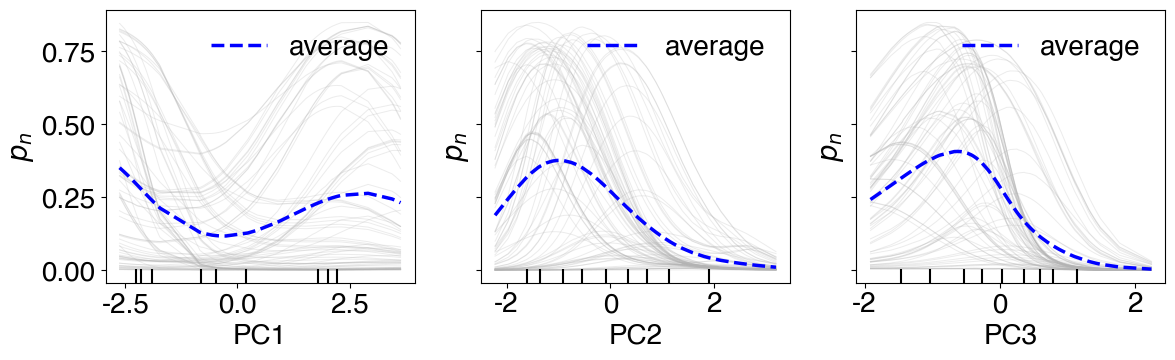

In [325]:
features_1d = [0, 1, 2]

fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

PartialDependenceDisplay.from_estimator(
    best_model, X_train_new, features=features_1d,
    feature_names=["PC1","PC2","PC3"],
    target=best_model.classes_[1],                 # multiclass needs target 
    response_method="predict_proba",
    kind="both",                           
    subsample=300, random_state=42,          
    grid_resolution=100,
    line_kw={"linewidth": 1.0},             # shared defaults 
    ice_lines_kw={"color": "0.7", "alpha": 0.25, "linewidth": 0.7},
    pd_line_kw={"color": "blue", "linewidth": 2.5},
    ax=ax
)

for a in ax:
    a.set_ylabel(r"$p_n$")
    a.legend(loc='upper right')
plt.tight_layout()
plt.savefig('/home/digifort/Pictures/paper_1_figs/upload/pdp_PC2.png', dpi = 600)
plt.savefig('/home/digifort/Pictures/paper_1_figs/upload/pdp_PC2.pdf', dpi = 600)
plt.show()


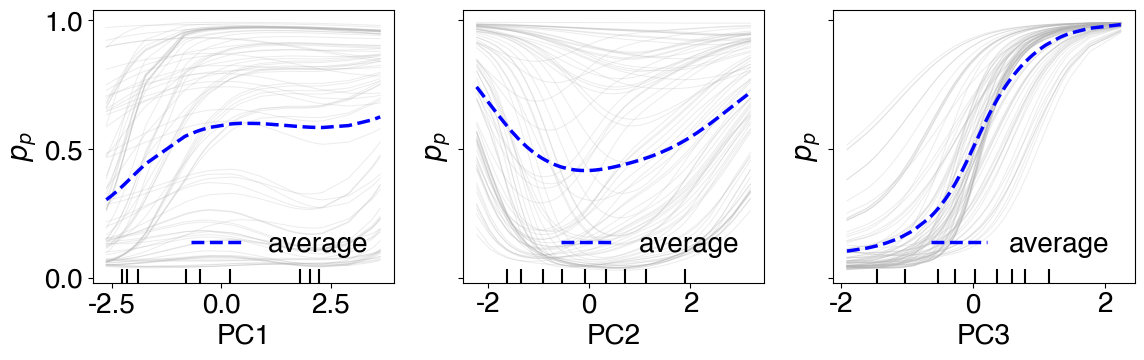

In [322]:
features_1d = [0, 1, 2]

fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

PartialDependenceDisplay.from_estimator(
    best_model, X_train, features=features_1d,
    feature_names=["PC1","PC2","PC3"],
    target=best_model.classes_[2],                
    response_method="predict_proba",
    kind="both",                           
    subsample=300, random_state=42,          
    grid_resolution=100,
    line_kw={"linewidth": 1.0},             
    ice_lines_kw={"color": "0.7", "alpha": 0.25, "linewidth": 0.7},
    pd_line_kw={"color": "blue", "linewidth": 2.5},
    ax=ax
)

for a in ax:
    a.set_ylabel(r"$p_p$")
    a.legend(loc='lower right')
plt.tight_layout()
plt.savefig('/home/digifort/Pictures/paper_1_figs/upload/pdp_PC3.png', dpi = 600)
plt.savefig('/home/digifort/Pictures/paper_1_figs/upload/pdp_PC3.pdf', dpi = 600)
plt.show()

### Held-out test set

In [27]:
clf = joblib.load('calibrated_svc.joblib')

In [28]:
df_hot = pd.read_csv('held_out_test.csv')

In [29]:
df_hot

,PC1,PC2,PC3,structures,structure_filenames,Defect_prcnt,Defect_type,dft_pred,btp_pred,clf_pred
0,1.845801,1.465224,-1.584795,1,te2_0.9_occupancy_i0_w8.cif,10.00%,$V_{Te2}$,p,p,NaN
1,3.226703,-0.780306,3.806656,19,bi1_0.85_occupancy_i003_w24.cif,15.00%,$V_{Bi1}$,weakly p,p,NaN
2,1.611100,2.998911,-0.305730,29,te2_0.8_occupancy_i02_w4.cif,20.00%,$V_{Te2}$,weakly p,p,NaN
3,0.081935,2.600175,-0.285400,34,te2_0.8_occupancy_i00_w12.cif,20.00%,$V_{Te2}$,weakly n,n,NaN
4,-4.076540,1.449381,0.716546,35,te2_0.8_occupancy_i01_w12.cif,20.00%,$V_{Te2}$,weakly p,p,NaN
5,-2.037010,-1.335123,-0.797835,44,te_0.15_bi_0.85_occupancy_i002_w24.cif,15.00%,$A_{Te_{Bi}}$,n,n,NaN
6,-2.288496,-1.672728,-0.580089,54,bi_0.15_te1_0.85_occupancy_i002_w24.cif,15.00%,$A_{Bi_{Te1}}$,i/weakly n,p,NaN
7,-2.268936,-1.539941,-0.677784,67,bi_0.1_te1_0.9_occupancy_i002_w24.cif,10.00%,$A_{Bi_{Te1}}$,i/weakly n,p,NaN
8,3.468124,-0.366591,-1.679374,70,te_0.15_bi_0.85_occupancy_i000_w8.cif,15.00%,$A_{Te_{Bi}}$,p,p,NaN
9,-2.097019,0.617192,1.060863,74,te1_0.8_occupancy_i001_w48.cif,20.00%,$V_{Te1}$,p,p,NaN


In [30]:
X = df_hot[['PC1', 'PC2', 'PC3']]

In [31]:
X

,PC1,PC2,PC3
0,1.845801,1.465224,-1.584795
1,3.226703,-0.780306,3.806656
2,1.611100,2.998911,-0.305730
3,0.081935,2.600175,-0.285400
4,-4.076540,1.449381,0.716546
5,-2.037010,-1.335123,-0.797835
6,-2.288496,-1.672728,-0.580089
7,-2.268936,-1.539941,-0.677784
8,3.468124,-0.366591,-1.679374
9,-2.097019,0.617192,1.060863


In [32]:
y_pred=clf.predict(X)

In [33]:
y_hot_calib_proba=clf.predict_proba(X)

In [34]:
df_hot['p_i'] = y_hot_calib_proba[:,0]
df_hot['p_n'] = y_hot_calib_proba[:,1]
df_hot['p_p'] = y_hot_calib_proba[:,2]

In [35]:
df_hot['clf_pred'] = y_pred

In [36]:
df_hot

,PC1,PC2,PC3,structures,structure_filenames,Defect_prcnt,Defect_type,dft_pred,btp_pred,clf_pred,p_i,p_n,p_p
0,1.845801,1.465224,-1.584795,1,te2_0.9_occupancy_i0_w8.cif,10.00%,$V_{Te2}$,p,p,i,0.519277,0.186709,0.294014
1,3.226703,-0.780306,3.806656,19,bi1_0.85_occupancy_i003_w24.cif,15.00%,$V_{Bi1}$,weakly p,p,p,0.116478,0.108422,0.775100
2,1.611100,2.998911,-0.305730,29,te2_0.8_occupancy_i02_w4.cif,20.00%,$V_{Te2}$,weakly p,p,p,0.275557,0.018767,0.705676
3,0.081935,2.600175,-0.285400,34,te2_0.8_occupancy_i00_w12.cif,20.00%,$V_{Te2}$,weakly n,n,p,0.278982,0.018119,0.702900
4,-4.076540,1.449381,0.716546,35,te2_0.8_occupancy_i01_w12.cif,20.00%,$V_{Te2}$,weakly p,p,p,0.251376,0.020480,0.728144
5,-2.037010,-1.335123,-0.797835,44,te_0.15_bi_0.85_occupancy_i002_w24.cif,15.00%,$A_{Te_{Bi}}$,n,n,n,0.221543,0.532045,0.246412
6,-2.288496,-1.672728,-0.580089,54,bi_0.15_te1_0.85_occupancy_i002_w24.cif,15.00%,$A_{Bi_{Te1}}$,i/weakly n,p,n,0.204775,0.542591,0.252634
7,-2.268936,-1.539941,-0.677784,67,bi_0.1_te1_0.9_occupancy_i002_w24.cif,10.00%,$A_{Bi_{Te1}}$,i/weakly n,p,n,0.209118,0.540801,0.250082
8,3.468124,-0.366591,-1.679374,70,te_0.15_bi_0.85_occupancy_i000_w8.cif,15.00%,$A_{Te_{Bi}}$,p,p,n,0.202129,0.548901,0.248970
9,-2.097019,0.617192,1.060863,74,te1_0.8_occupancy_i001_w48.cif,20.00%,$V_{Te1}$,p,p,p,0.230697,0.023666,0.745637


In [37]:
df_hot.to_csv('hot.csv', index=False)